# Figure S10

The TSS model against every per-sample covariate we could obtain, for both tasks (BRCA/CRC: 164
healthy vs 80 cancer; PANCAN: 164 vs 203):

1. Baselines vs the model: every covariate from our pipeline and the Cristiano et al. 2019 supplement,
   alone and as multivariate panels, on the same frozen outer folds as the fully nested model, so every
   comparison is paired.
2. The covariates among themselves and the deep-sequenced subgroup.
3. Spearman correlations between the pooled out-of-fold posteriors and every covariate, pooled and
   within class.

Section 6 assembles Figure S10; Section 7 draws Fig S10a and b on one axis.

Covariates are grouped as technical (sequencing / pre-analytical), demographic and biologically
informed, plus clinical stage in Section 3. The Cristiano supplement has no batch annotation; the 30
healthy samples sequenced about four times deeper are the one de facto batch.

Sources: `data/fig3_baseline_*.csv`, `data/fig4_baseline_*.csv`, `data/tableS3_*.csv` (from
`export/export_fig3_baselines.py --task brca_crc|pancan`), `data/fig3_predictions.csv` (the BRCA/CRC
model) and `data/figS10_depth_subgroup.csv` (from `export/export_figS10_subgroup.py`).

Protocols. Univariate covariate: per outer fold, train-median imputation, orientation = the sign that
makes the train AUROC >= 0.5, threshold = lowest cutoff with train specificity >= 0.95. Panels: the
covariate subset as one predefined matrix through the same nested CV as the ATAC arm (same fold
generator, all six classifiers with full grids, classifier chosen per outer fold on inner-CV scores;
`--predefined_no_row_standardize`, per-feature scaling on training folds). ichorCNA tumor fraction is
its own baseline and never part of a panel.

In [1]:
import os

# Data paths are relative to src/figures/; hop there if the kernel started elsewhere
# (e.g. VSCode with jupyter.notebookFileRoot = workspaceFolder).
if not os.path.isdir("data") and os.path.isdir(os.path.join("src", "figures", "data")):
    os.chdir(os.path.join("src", "figures"))

# --- cohort switch ------------------------------------------------------------------
# "no_deep" (default): without the 30 deep-sequenced healthy controls (exporters run with
# COHORT_VARIANT=no_deep, data/no_deep/); "all": the full cohort. Set COHORT here or FIG_COHORT
# in the environment. A file not exported for the variant falls back to the full-cohort file,
# with a notice. Figures go to output/<variant>/.

COHORT = os.environ.get("FIG_COHORT", "no_deep")
assert COHORT in ("all", "no_deep"), COHORT
_DATA = "data" if COHORT == "all" else os.path.join("data", COHORT)
_OUT = "output" if COHORT == "all" else os.path.join("output", COHORT)
os.makedirs(_OUT, exist_ok=True)
_FALLBACKS = set()


def data_path(name):
    """Source-data path for the selected cohort (full-cohort fallback with a notice)."""
    p = os.path.join(_DATA, name)
    if COHORT != "all" and not os.path.exists(p):
        if name not in _FALLBACKS:
            print(f"   [cohort {COHORT}] {name} not exported for this cohort - using the full-cohort file")
            _FALLBACKS.add(name)
        p = os.path.join("data", name)
    return p


def out_path(name):
    """Output path for the selected cohort."""
    return os.path.join(_OUT, name)


print(f"cohort: {COHORT} (source data from {_DATA}/, figures to {_OUT}/)")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from scipy.stats import mannwhitneyu, fisher_exact, spearmanr, false_discovery_control
from sklearn.metrics import roc_curve, auc, roc_auc_score as roc_auc

CATEGORIES = {
    "mean_coverage": "technical", "total_fragments": "technical",
    "plasma_volume": "technical",
    "age": "demographic", "sex_female": "demographic",
    "fragment_length_mean": "biological", "mean_gc": "biological",
    "cfdna_extracted": "biological",
    "ichorcna_tf": "biological",
}
SCALARS = list(CATEGORIES)
LABELS = {
    "mean_coverage": "Mean coverage", "total_fragments": "Total fragments",
    "plasma_volume": "Plasma volume",
    "age": "Age", "sex_female": "Sex",
    "fragment_length_mean": "Fragment length (mean)", "mean_gc": "Mean fragment GC",
    "cfdna_extracted": "cfDNA concentration",
    "ichorcna_tf": "ichorCNA TF",
}
UNITS = {
    "mean_coverage": "x", "total_fragments": "", "plasma_volume": "ml",
    "age": "years", "sex_female": "", "fragment_length_mean": "bp", "mean_gc": "%",
    "cfdna_extracted": "ng/ml", "ichorcna_tf": "",
}
CAT_COLORS = {"technical": "#4D4D4D", "demographic": "#B0489B",
              "biological": "#2E7D32", "clinical": "#B8860B"}
# per-scalar hues follow the category family (greys / pink+teal / greens+browns)
SCALAR_COLORS = {
    "mean_coverage": "#7F7F7F", "total_fragments": "#4D4D4D",
    "plasma_volume": "#C8C8C8",
    "age": "#E377C2", "sex_female": "#17BECF",
    "fragment_length_mean": "#2CA02C", "mean_gc": "#8C564B",
    "cfdna_extracted": "#BCBD22", "ichorcna_tf": "#6A3D9A",
}
# Multivariate panels: label, color, drawn in the ROC (principal panels only),
# evaluated on the frozen folds (the complete-case sensitivity arm uses a
# reduced cohort with its own outer folds).
PANELS = {
    "bl_panel_all8": dict(label="All 8 measures", color="#D55E00", roc=True, frozen=True),
    "bl_panel_technical3": dict(label="Technical panel (3)", color="#4D4D4D", roc=True, frozen=True),
    "bl_panel_biological3": dict(label="Cancer-associated panel (3)", color="#1B5E20", roc=False, frozen=True),
    "bl_panel_demographic": dict(label="Demographic panel (2)", color="#B0489B", roc=True, frozen=True),
    "bl_panel_full6": dict(label="Pipeline + demographics panel (6)", color="#8A7F00", roc=True, frozen=True),
    "bl_panel_techdemo5": dict(label="Technical + demographic panel (5)", color="#3B4A8C", roc=True, frozen=True),
    "bl_panel_complete5": dict(label="Complete measures only (5, no imputation)", color="#E69F00", roc=False, frozen=True),
    "bl_panel_all8_cc": dict(label="All 8, complete cases (no imputation)", color="#FDDBC7",
                             roc=False, frozen=False, subset="cc"),
    "bl_panel_pipeline4": dict(label="Pipeline panel (4, cohort-transferable)", color="#2A9FD6", roc=False, frozen=True),
    "bl_panel_transfer5": dict(label="Cohort-transferable panel (5)", color="#1F78B4", roc=True, frozen=True),
}
# the cohort-transferable covariates (pipeline4 + genetic sex from the BAM)
TRANSFER5 = ["mean_coverage", "total_fragments", "fragment_length_mean", "mean_gc", "sex_female_bam"]
JIANG_COVS = list(TRANSFER5)
# sex_female_bam is a transferable-panel covariate only (not a univariate arm of Sections 1-3)
LABELS["sex_female_bam"] = "Sex (from the BAM)"
UNITS["sex_female_bam"] = "1 = female"
SCALAR_COLORS["sex_female_bam"] = "#17BECF"
CATEGORIES_EXTRA = {"sex_female_bam": "demographic"}
CAT_OF = lambda c: CATEGORIES.get(c, {"sex_female_bam": "demographic"}.get(c, "biological"))
ALL8 = ["mean_coverage", "total_fragments", "plasma_volume", "age",
        "sex_female", "fragment_length_mean", "mean_gc", "cfdna_extracted"]
TECH3 = ["mean_coverage", "total_fragments", "plasma_volume"]
MODEL_COLOR = "#0173B2"
TASKS = ["BRCA/CRC", "PANCAN"]

# --- load everything ---------------------------------------------------------
# The BRCA/CRC data-driven arm comes from fig3_predictions.csv (export_fig3.py); if that file is
# missing for the cohort, the arm is left out (HAVE_DD False).
_have_fig3 = COHORT == "all" or os.path.exists(os.path.join(_DATA, "fig3_predictions.csv"))
fig3_pred = pd.read_csv(data_path("fig3_predictions.csv")) if _have_fig3 else None
arms = {
    "BRCA/CRC": pd.concat(([
        fig3_pred[(fig3_pred["method"] == "data_driven") & fig3_pred["fold"].notna()]
        [["sample_id", "method", "fold", "y_true", "score", "threshold_95spec"]]] if _have_fig3 else []) + [
        pd.read_csv(data_path("fig3_baseline_predictions.csv"))
        [["sample_id", "method", "fold", "y_true", "score", "threshold_95spec", "orientation"]],
    ], ignore_index=True),
    "PANCAN": pd.read_csv(data_path("fig4_baseline_predictions.csv"))
    [["sample_id", "method", "fold", "y_true", "score", "threshold_95spec", "orientation"]],
}
# PANCAN data-driven arm: from the baselines export if present, else from the Fig S14 export
# (export_figS14.py; same model with its per-fold thresholds). Under no_deep: the ksweep_tuned/ arm.
if not (arms["PANCAN"]["method"] == "data_driven").any() and os.path.exists(os.path.join(_DATA, "figS14_predictions.csv")):
    # fig4a_predictions.csv has no per-fold threshold; figS14_predictions.csv (arm none at the
    # tuned k per fold = the same ksweep_tuned model) carries the train-derived 95%-spec threshold
    _p = pd.read_csv(os.path.join(_DATA, "figS14_predictions.csv")); _t = pd.read_csv(os.path.join(_DATA, "figS14_tuned.csv"))
    _t = _t[(_t["task"] == "pancan") & (_t["arm"] == "none")]
    _p = _p[(_p["task"] == "pancan") & (_p["arm"] == "none")].merge(_t[["fold", "k_selected"]], on="fold")
    _p = _p[_p["k"] == _p["k_selected"]].assign(method="data_driven")[["sample_id", "method", "fold", "y_true", "score", "threshold_95spec"]]
    if os.path.exists(os.path.join(_DATA, "fig4a_predictions.csv")):   # same model: the scores must agree
        _f5 = pd.read_csv(os.path.join(_DATA, "fig4a_predictions.csv")); _f5 = _f5[_f5["method"] == "data_driven"].set_index("sample_id")["score"]
        assert len(_p) == len(_f5) and np.allclose(_p.set_index("sample_id")["score"].reindex(_f5.index), _f5), "figS14 tuned arm differs from fig4a_predictions.csv"
    arms["PANCAN"] = pd.concat([_p, arms["PANCAN"]], ignore_index=True)
    print(f"   PANCAN data-driven arm taken from figS14_predictions.csv at the tuned k ({len(_p)} rows; scores verified against fig4a_predictions.csv)")
HAVE_DD = {task: bool((arms[task]["method"] == "data_driven").any()) for task in TASKS}
from scipy.stats import rankdata   # within-fold percentile ranks
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
# the trained arms and their labels, used by the later sections
TRAINED = ["data_driven", "bl_panel_all8", "bl_panel_technical3", "bl_panel_techdemo5",
           "bl_panel_biological3", "bl_panel_demographic", "bl_panel_full6", "bl_panel_pipeline4",
           "bl_panel_transfer5"]
TRAINED = [m for m in TRAINED if any((arms[t]["method"] == m).any() for t in TASKS)]
TR_LABEL = {"data_driven": "Data-driven model", **{m: PANELS[m]["label"].split(" (")[0].replace(" measures", "") for m in TRAINED[1:]}}
UNIV = [f"bl_{c}" for c in SCALARS]
if not all(HAVE_DD.values()):
    print(f"   NOTE: data-driven arm not available for this cohort yet: "
          f"{[t for t, v in HAVE_DD.items() if not v]} (fully nested run pending)")
scalars = {"BRCA/CRC": pd.read_csv(data_path("fig3_baseline_scalars.csv")),
           "PANCAN": pd.read_csv(data_path("fig4_baseline_scalars.csv"))}
tables = {"BRCA/CRC": pd.read_csv(data_path("tableS3_baselines.csv")),
          "PANCAN": pd.read_csv(data_path("tableS3_baselines_pancan.csv"))}
for task in TASKS:
    a = arms[task]
    a["fold"] = a["fold"].astype(int)
    present = set(a["method"])
    missing_panels = [m for m in PANELS if m not in present]
    print(f"{task}: {a['sample_id'].nunique()} samples, methods: {sorted(present)}")
    if missing_panels:
        print(f"   NOTE: panel arms not exported yet: {missing_panels}")


def fold_rocs(df):
    out = []
    for _, g in df.groupby("fold"):
        fpr, tpr, _ = roc_curve(g["y_true"], g["score"])
        out.append((fpr, tpr, auc(fpr, tpr)))
    return out


def mean_roc(df):
    base_fpr = np.linspace(0, 1, 101)
    tprs, aucs = [], []
    for fpr, tpr, a in fold_rocs(df):
        tprs.append(interp1d(fpr, tpr, kind="linear")(base_fpr))
        aucs.append(a)
    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[0], mean_tpr[-1] = 0, 1
    return base_fpr, mean_tpr, np.array(aucs)


def arm(task, method):
    return arms[task][arms[task]["method"] == method]

cohort: no_deep (source data from data\no_deep/, figures to output\no_deep/)


BRCA/CRC: 244 samples, methods: ['bl_age', 'bl_cfdna_extracted', 'bl_fragment_length_mean', 'bl_ichorcna_tf', 'bl_mean_coverage', 'bl_mean_gc', 'bl_panel_all8', 'bl_panel_all8_cc', 'bl_panel_biological3', 'bl_panel_complete5', 'bl_panel_demographic', 'bl_panel_full6', 'bl_panel_pipeline4', 'bl_panel_techdemo5', 'bl_panel_technical3', 'bl_panel_transfer5', 'bl_plasma_volume', 'bl_sex_female', 'bl_total_fragments', 'data_driven']
PANCAN: 367 samples, methods: ['bl_age', 'bl_cfdna_extracted', 'bl_fragment_length_mean', 'bl_ichorcna_tf', 'bl_mean_coverage', 'bl_mean_gc', 'bl_panel_all8', 'bl_panel_all8_cc', 'bl_panel_biological3', 'bl_panel_complete5', 'bl_panel_demographic', 'bl_panel_full6', 'bl_panel_pipeline4', 'bl_panel_techdemo5', 'bl_panel_technical3', 'bl_panel_transfer5', 'bl_plasma_volume', 'bl_sex_female', 'bl_total_fragments', 'data_driven']


## 1. Baselines vs the model

Two kinds of arms, on the same ten outer folds per task:

- Trained classifiers, fully nested CV (solid lines; bold in the bar chart): the data-driven TSS model
  and the covariate panels (classifier and hyperparameters chosen inside each outer fold from the same
  six candidates).
- Single covariates (dashed lines, hue = category): the covariate itself is the score; only its sign
  and the 95%-specificity threshold are learned on the training folds.

Panel compositions:
- Technical (3): mean coverage, total fragments, plasma volume.
- Demographic (2): age, sex.
- Cancer-associated (3): fragment length, mean fragment GC, cfDNA concentration.
- All 8: the technical, demographic and cancer-associated covariates (no ichorCNA TF).
- Pipeline + demographics (6): mean coverage, total fragments, fragment length, mean GC, age, sex (no
  Cristiano-supplement columns).
- Technical + demographic (5): the three technical covariates plus age and sex.
- Complete covariates only (5): the five covariates with no missing value in either task (nothing imputed).
- All 8, complete cases: all eight covariates, every sample with a missing value dropped (reduced
  cohort, hence its own outer folds).
- Cohort-transferable (4): mean coverage, total fragments, fragment length and mean GC (defined the
  same way in every cohort, e.g. Jiang); Cohort-transferable (5) adds genetic sex inferred from the BAM.

Legend AUROCs are mean +/- SD over folds. The audit cell re-derives every univariate orientation and
threshold from the raw covariates using training folds only and asserts that the exported predictions
match.

In [2]:
# --- protocol audit: re-derive the univariate arms from raw scalars ---------
for task in TASKS:
    sc, a = scalars[task], arms[task]
    for col in SCALARS:
        dfm = a[a["method"] == f"bl_{col}"]
        for f in sorted(sc["fold"].unique()):
            tr, te = sc[sc["fold"] != f], sc[sc["fold"] == f]
            med = tr[col].median()
            x_tr, y_tr = tr[col].fillna(med).to_numpy(float), tr["y_true"].to_numpy(int)
            o = 1.0 if auc(*roc_curve(y_tr, x_tr)[:2]) >= 0.5 else -1.0
            fpr_o, _, thr_o = roc_curve(y_tr, o * x_tr)
            thr = thr_o[np.where(1 - fpr_o >= 0.95)[0][-1]]
            g = dfm[dfm["fold"] == f].set_index("sample_id")
            exp_scores = o * te.set_index("sample_id")[col].fillna(med)
            assert np.allclose(g.loc[exp_scores.index, "score"], exp_scores), (task, col, f)
            assert np.isclose(g["threshold_95spec"].iloc[0], thr), (task, col, f)
            assert (g["orientation"] == o).all(), (task, col, f)
    # panels and the model: every fold's test set must be exactly one frozen fold
    # (the complete-case sensitivity arm runs on a reduced cohort with its own folds)
    fold_of = dict(zip(sc["sample_id"], sc["fold"]))
    for m in (["data_driven"] if HAVE_DD[task] else []) + [p for p, c in PANELS.items() if c["frozen"] and (a["method"] == p).any()]:
        g = a[a["method"] == m]
        assert all(fold_of[s] == f for s, f in zip(g["sample_id"], g["fold"])), (task, m)
        assert len(g) == len(sc), (task, m, len(g))
    n_cc = int(sc[ALL8].notna().all(axis=1).sum())
    sci = sc.set_index("sample_id")
    for m in [p for p, c in PANELS.items() if not c["frozen"] and (a["method"] == p).any()]:
        g = a[a["method"] == m]
        assert g["sample_id"].is_unique and set(g["sample_id"]) <= set(sc["sample_id"]), (task, m)
        assert len(g) == n_cc and sci.loc[g["sample_id"], ALL8].notna().all().all(), (task, m)
    print(f"{task}: protocol audit passed (univariate orientation/threshold re-derived "
          "train-only; model and panel arms on the frozen folds; "
          f"complete-case arm on {n_cc} samples)")

BRCA/CRC: protocol audit passed (univariate orientation/threshold re-derived train-only; model and panel arms on the frozen folds; complete-case arm on 235 samples)
PANCAN: protocol audit passed (univariate orientation/threshold re-derived train-only; model and panel arms on the frozen folds; complete-case arm on 346 samples)


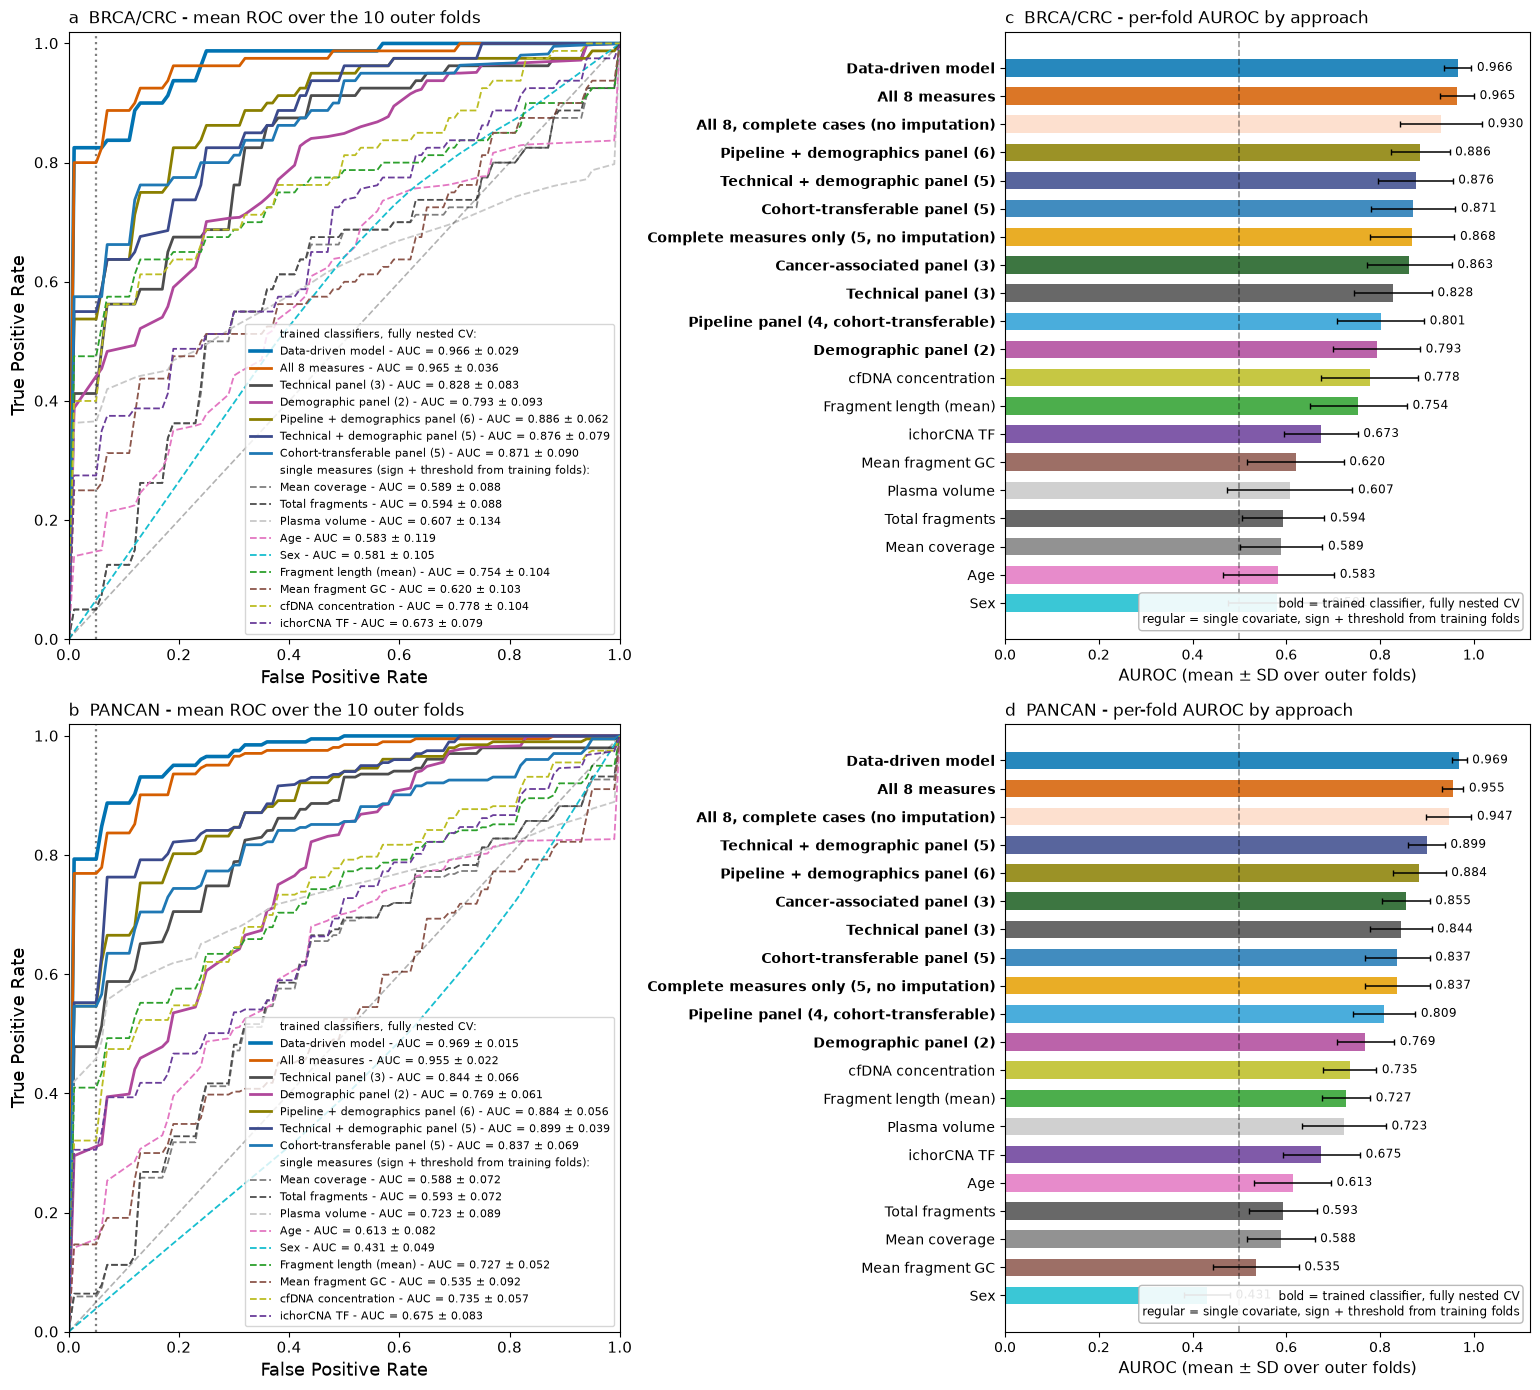

In [3]:
# --- Figure S10a: ROC + AUROC by approach, both tasks -------------------------
fig, axes = plt.subplots(2, 2, figsize=(15.5, 14), gridspec_kw={"width_ratios": [1.05, 1]})
for r, task in enumerate(TASKS):
    a = arms[task]
    ax = axes[r, 0]
    ax.plot([], [], " ", label="trained classifiers, fully nested CV:")
    if HAVE_DD[task]:
        x, y, aucs = mean_roc(arm(task, "data_driven"))
        ax.plot(x, y, color=MODEL_COLOR, linewidth=2.6,
                label=f"Data-driven model - AUC = {aucs.mean():.3f} ± {aucs.std():.3f}")
    for m, c in PANELS.items():
        if not c["roc"] or not (a["method"] == m).any():
            continue
        x, y, aucs = mean_roc(arm(task, m))
        ax.plot(x, y, color=c["color"], linewidth=2.0,
                label=f"{c['label']} - AUC = {aucs.mean():.3f} ± {aucs.std():.3f}")
    ax.plot([], [], " ", label="single measures (sign + threshold from training folds):")
    for col in SCALARS:
        x, y, aucs = mean_roc(arm(task, f"bl_{col}"))
        ax.plot(x, y, color=SCALAR_COLORS[col], linewidth=1.3, linestyle="--",
                label=f"{LABELS[col]} - AUC = {aucs.mean():.3f} ± {aucs.std():.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, linewidth=1.2)
    ax.axvline(x=0.05, color="dimgray", linestyle=":", linewidth=1.6, alpha=0.85, zorder=1)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate", fontsize=13)
    ax.set_ylabel("True Positive Rate", fontsize=13)
    ax.legend(loc="lower right", fontsize=7.8, frameon=True, ncol=1)
    ax.tick_params(labelsize=10.5)
    ax.set_title(f"{'ab'[r]}  {task} - mean ROC over the 10 outer folds", loc="left", fontsize=12.5)

    ax = axes[r, 1]
    rows = []
    for m in [f"bl_{c}" for c in SCALARS] + [p for p in PANELS if (a["method"] == p).any()] + (["data_driven"] if HAVE_DD[task] else []):
        aucs = np.array([x[2] for x in fold_rocs(arm(task, m))])
        if m == "data_driven":
            label, color = "Data-driven model", MODEL_COLOR
        elif m in PANELS:
            label, color = PANELS[m]["label"], PANELS[m]["color"]
        else:
            col = m[3:]
            label, color = LABELS[col], SCALAR_COLORS[col]
        rows.append((label, aucs.mean(), aucs.std(), color, m in PANELS or m == "data_driven"))
    rows.sort(key=lambda t: t[1])
    ypos = np.arange(len(rows))
    ax.barh(ypos, [t[1] for t in rows], xerr=[t[2] for t in rows],
            color=[t[3] for t in rows], alpha=0.85,
            height=0.62, error_kw={"elinewidth": 1.1, "capsize": 2.5})
    ax.set_yticks(ypos)
    ax.set_yticklabels([t[0] for t in rows], fontsize=9.5)
    for tick, t in zip(ax.get_yticklabels(), rows):
        if t[4]:
            tick.set_fontweight("bold")
    ax.axvline(0.5, color="k", linestyle="--", alpha=0.4, linewidth=1.2)
    ax.set_xlim(0, 1.12); ax.set_xticks(np.arange(0, 1.01, 0.2))
    ax.set_xlabel("AUROC (mean ± SD over outer folds)", fontsize=11.5)
    ax.set_title(f"{'cd'[r]}  {task} - per-fold AUROC by approach", loc="left", fontsize=12.5)
    ax.tick_params(labelsize=10)
    for t, y0 in zip(rows, ypos):
        ax.text(t[1] + t[2] + 0.012, y0, f"{t[1]:.3f}", va="center", fontsize=8.5)
    ax.text(0.98, 0.02, "bold = trained classifier, fully nested CV\nregular = single covariate, sign + threshold from training folds",
            transform=ax.transAxes, fontsize=8.5, va="bottom", ha="right",
            bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.7", alpha=0.9))
plt.tight_layout()
fig.savefig(out_path("figS10_roc.png"), dpi=300, bbox_inches="tight")
fig.savefig(out_path("figS10_roc.pdf"), bbox_inches="tight")
plt.show()

In [4]:
# --- Table: every arm, both tasks (Table S3 source CSVs) ----------------------
def fmt(tab):
    show = tab.copy()
    show["AUROC (folds)"] = show.apply(lambda r: f"{r['auc_fold_mean']:.3f} +/- {r['auc_fold_sd']:.3f}", axis=1)
    show["Sens@95%spec"] = show.apply(lambda r: f"{r['sensitivity_95spec_mean']:.3f} +/- {r['sensitivity_95spec_sd']:.3f}", axis=1)
    show["Spec (test)"] = show.apply(lambda r: f"{r['specificity_95spec_mean']:.3f} +/- {r['specificity_95spec_sd']:.3f}", axis=1)
    cols = ["method", "category", "protocol", "AUROC (folds)", "auc_pooled_oof", "Sens@95%spec", "Spec (test)"]
    if "selected_classifier" in show.columns:
        cols.insert(3, "selected_classifier")
    return show[cols].round(3)

for task in TASKS:
    tab = tables[task]
    # consistency: table AUROCs reproduce from the per-sample predictions
    for _, r in tab.iterrows():
        if r["method"] in ("rna", "atac", "ichorcna"):
            continue  # brca_crc hypothesis-driven arms live in fig3.ipynb
        aucs = np.array([x[2] for x in fold_rocs(arm(task, r["method"]))])
        assert np.isclose(aucs.mean(), r["auc_fold_mean"], atol=1e-9), (task, r["method"])
    print(f"=== {task} ===")
    display(fmt(tab))

=== BRCA/CRC ===


,method,category,protocol,selected_classifier,AUROC (folds),auc_pooled_oof,Sens@95%spec,Spec (test)
0,data_driven,model,nested_cv,NaN,0.966 +/- 0.029,0.960,0.812 +/- 0.128,0.951 +/- 0.037
1,rna,model,nested_cv,NaN,0.666 +/- 0.108,0.613,0.138 +/- 0.131,0.903 +/- 0.092
2,atac,model,nested_cv,NaN,0.891 +/- 0.096,0.892,0.675 +/- 0.225,0.933 +/- 0.043
3,ichorcna,competing_method,raw_score_legacy,NaN,0.673 +/- 0.079,0.672,0.300 +/- 0.195,0.964 +/- 0.061
4,bl_panel_full6,panel (pipeline + demographics),nested_cv,per-fold (inner CV): XGBoost x10,0.886 +/- 0.062,0.884,0.625 +/- 0.209,0.933 +/- 0.042
5,bl_panel_technical3,panel (technical),nested_cv,per-fold (inner CV): Multi-Layer Perceptron x5...,0.828 +/- 0.083,0.821,0.400 +/- 0.166,0.957 +/- 0.049
6,bl_panel_demographic,panel (demographic),nested_cv,per-fold (inner CV): XGBoost x10,0.793 +/- 0.093,0.780,0.325 +/- 0.160,0.963 +/- 0.049
7,bl_panel_techdemo5,panel (technical + demographic),nested_cv,"per-fold (inner CV): XGBoost x8, Support Vecto...",0.876 +/- 0.079,0.881,0.537 +/- 0.138,0.950 +/- 0.073
8,bl_panel_all8,panel (all covariates),nested_cv,"per-fold (inner CV): XGBoost x6, Support Vecto...",0.965 +/- 0.036,0.961,0.838 +/- 0.148,0.944 +/- 0.059
9,bl_panel_complete5,panel (no imputation),nested_cv,per-fold (inner CV): Support Vector Machine x8...,0.868 +/- 0.091,0.859,0.550 +/- 0.218,0.933 +/- 0.069


=== PANCAN ===


,method,category,protocol,selected_classifier,AUROC (folds),auc_pooled_oof,Sens@95%spec,Spec (test)
0,data_driven,model,nested_cv,NaN,0.969 +/- 0.015,0.967,0.813 +/- 0.081,0.976 +/- 0.030
1,bl_panel_full6,panel (pipeline + demographics),nested_cv,per-fold (inner CV): XGBoost x10,0.884 +/- 0.056,0.884,0.566 +/- 0.069,0.945 +/- 0.057
2,bl_panel_technical3,panel (technical),nested_cv,per-fold (inner CV): Support Vector Machine x4...,0.844 +/- 0.066,0.834,0.549 +/- 0.183,0.951 +/- 0.060
3,bl_panel_demographic,panel (demographic),nested_cv,per-fold (inner CV): XGBoost x10,0.769 +/- 0.061,0.759,0.296 +/- 0.099,0.969 +/- 0.031
4,bl_panel_techdemo5,panel (technical + demographic),nested_cv,"per-fold (inner CV): XGBoost x9, Multi-Layer P...",0.899 +/- 0.039,0.889,0.640 +/- 0.113,0.957 +/- 0.056
5,bl_panel_all8,panel (all covariates),nested_cv,per-fold (inner CV): XGBoost x10,0.955 +/- 0.022,0.954,0.804 +/- 0.092,0.957 +/- 0.063
6,bl_panel_complete5,panel (no imputation),nested_cv,per-fold (inner CV): Support Vector Machine x10,0.837 +/- 0.069,0.836,0.630 +/- 0.100,0.921 +/- 0.103
7,bl_panel_all8_cc,"panel (all covariates, complete cases only)",nested_cv,"per-fold (inner CV): XGBoost x9, Multi-Layer P...",0.947 +/- 0.048,0.946,0.807 +/- 0.144,0.957 +/- 0.063
8,bl_panel_pipeline4,"panel (pipeline, cohort-transferable)",nested_cv,per-fold (inner CV): Support Vector Machine x9...,0.809 +/- 0.067,0.807,0.517 +/- 0.070,0.921 +/- 0.089
9,bl_panel_biological3,panel (cancer-associated measurements),nested_cv,per-fold (inner CV): Support Vector Machine x6...,0.855 +/- 0.051,0.850,0.576 +/- 0.088,0.926 +/- 0.101


### 1g. Do the model and the covariate panels score the same samples alike?

Scores are converted to within-fold percentile ranks (the winning classifier, and with it the score
scale, differs between folds) and correlated within class, since a pooled correlation is inflated by
both scores separating the classes. Left: the model against the all-8 panel. Middle and right: Spearman
between every pair of trained arms within healthy and within cancer; panels that share inputs serve as
a reference.

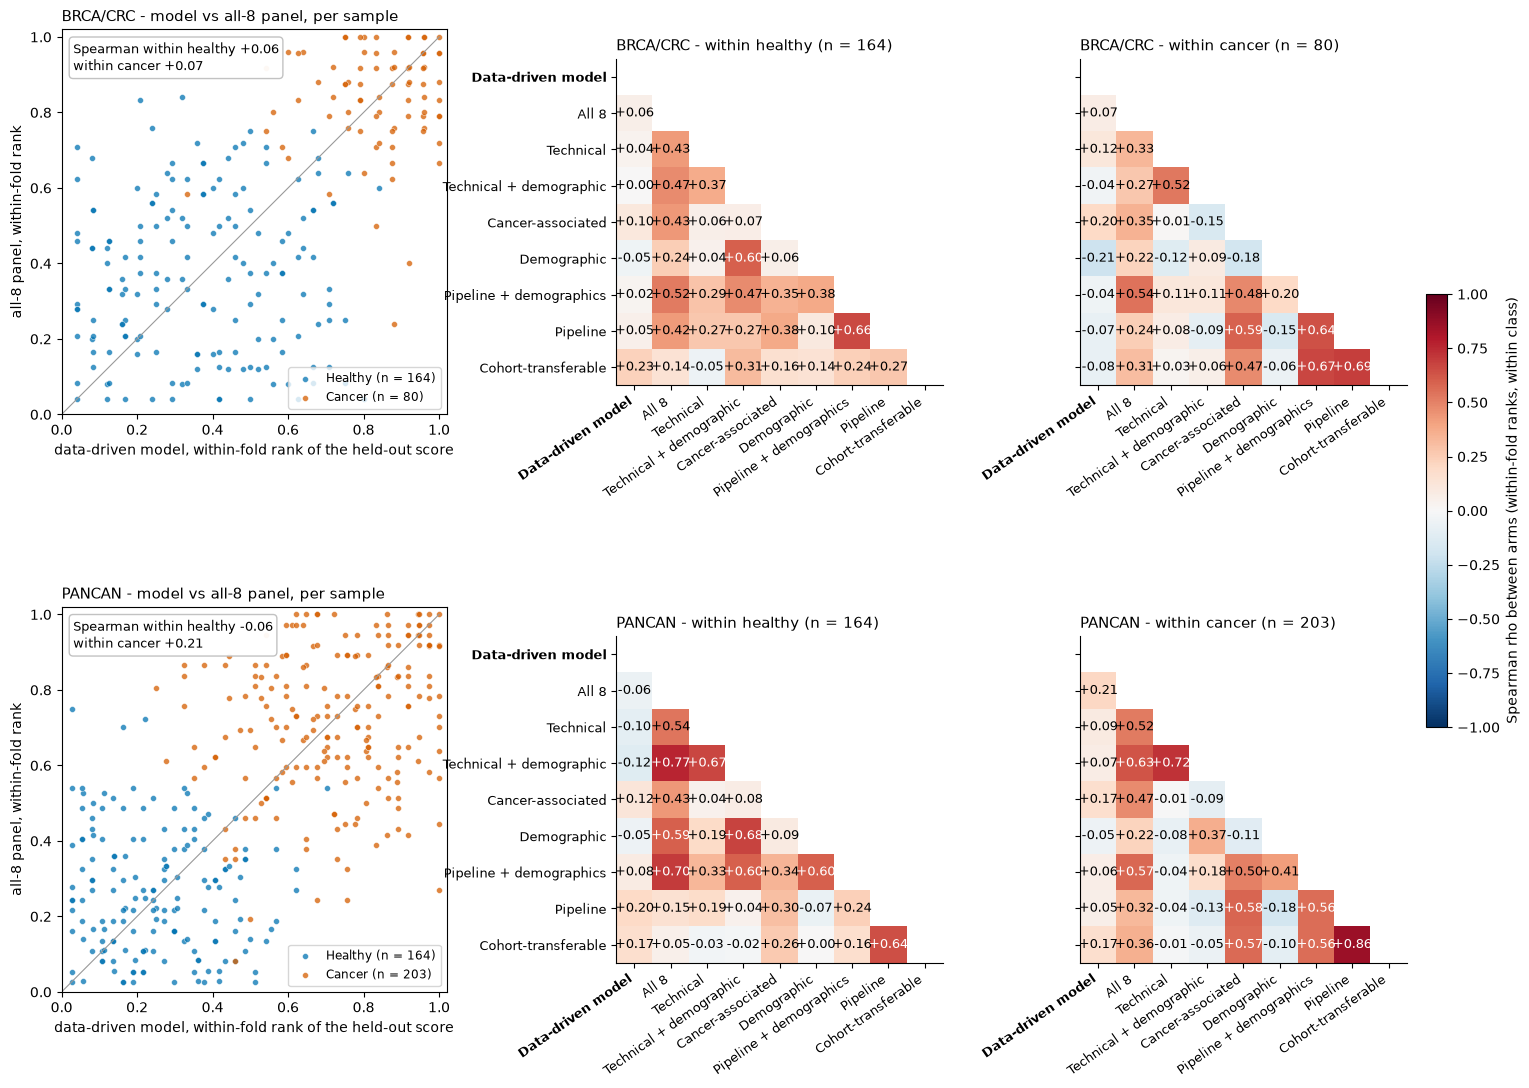

Reference - the all-8 panel against its own sub-panels, within class: BRCA/CRC vs technical3 healthy +0.43; BRCA/CRC vs technical3 cancer +0.33; BRCA/CRC vs biological3 healthy +0.43; BRCA/CRC vs biological3 cancer +0.35; PANCAN vs technical3 healthy +0.54; PANCAN vs technical3 cancer +0.52; PANCAN vs biological3 healthy +0.43; PANCAN vs biological3 cancer +0.47
Spearman between the data-driven model's held-out score and each covariate panel's (within-fold ranks)


,task,panel,pooled (both classes),healthy,p (healthy),cancer,p (cancer),per-fold median (healthy),per-fold median (cancer)
0,BRCA/CRC,All 8,0.598,0.057,0.467,0.071,0.530,0.044,0.214
1,BRCA/CRC,Technical panel,0.444,0.038,0.631,0.117,0.303,0.049,0.048
2,BRCA/CRC,Technical + demographic panel,0.478,0.004,0.960,-0.037,0.746,0.045,-0.036
3,BRCA/CRC,Cancer-associated panel,0.514,0.103,0.190,0.197,0.080,0.042,0.131
4,BRCA/CRC,Demographic panel,0.311,-0.047,0.551,-0.206,0.066,0.028,-0.241
5,BRCA/CRC,Pipeline + demographics panel,0.488,0.025,0.752,-0.043,0.703,0.046,-0.119
6,BRCA/CRC,Pipeline panel,0.392,0.052,0.511,-0.074,0.514,0.022,0.012
7,BRCA/CRC,Cohort-transferable panel,0.537,0.232,0.003,-0.077,0.497,0.209,-0.071
8,PANCAN,All 8,0.671,-0.060,0.447,0.207,0.003,-0.022,0.269
9,PANCAN,Technical panel,0.496,-0.095,0.225,0.091,0.199,-0.037,0.131


In [5]:
if not all(HAVE_DD.values()):
    print("Section 1g is skipped: the data-driven arm is not exported for this cohort yet")
else:
    # --- 1g: model vs covariate-panel scores, sample by sample ------------------------
    DEEP_COVERAGE_X = 6.0   # the 30 deep-sequenced healthy samples; the cohort has no sample between 5.3x and 6.3x
    deep_ids = set(scalars["PANCAN"].loc[scalars["PANCAN"]["mean_coverage"] > DEEP_COVERAGE_X, "sample_id"])
    N_DEEP_EXPECTED = 30 if COHORT == "all" else 0   # the subgroup is excluded from the no_deep cohort
    assert len(deep_ids) == N_DEEP_EXPECTED and (scalars["PANCAN"].set_index("sample_id").loc[list(deep_ids), "y_true"] == 0).all()
    G3_COLORS = {"Healthy": "#0173B2", "Healthy, deep-sequenced": "#029E73", "Cancer": "#D55E00"}

    def fold_ranks(task, methods):
        """Scores as within-fold percentile ranks (classifiers differ between folds, so raw
        scores are not on one scale): one column per method, indexed by sample."""
        a = arms[task][arms[task]["method"].isin(methods)].copy()
        a["fold_rank"] = a.groupby(["method", "fold"])["score"].transform(lambda s: rankdata(s) / len(s))
        return a.pivot(index="sample_id", columns="method", values="fold_rank")[methods]

    sim_rows, SIM = [], {}
    fig, axes = plt.subplots(2, 3, figsize=(19.5, 12.5), gridspec_kw=dict(width_ratios=[1.0, 1.0, 1.0], wspace=0.42, hspace=0.5))
    for r, task in enumerate(TASKS):
        trained_here = [m for m in TRAINED if (arms[task]["method"] == m).any()]
        Rk = fold_ranks(task, trained_here)
        info = scalars[task].set_index("sample_id").loc[Rk.index]
        y = info["y_true"].astype(int); fold = info["fold"].astype(int)
        deep = pd.Series(Rk.index.isin(deep_ids), index=Rk.index)
        scopes = {"healthy": y == 0, **({"healthy, deep excluded": (y == 0) & ~deep} if N_DEEP_EXPECTED else {}), "cancer": y == 1}
        for other in trained_here[1:]:
            row = {"task": task, "panel": TR_LABEL[other]}
            for nm, mask in scopes.items():
                rho, p = spearmanr(Rk.loc[mask, "data_driven"], Rk.loc[mask, other])
                per_fold = [spearmanr(Rk.loc[mask & (fold == f), "data_driven"], Rk.loc[mask & (fold == f), other])[0]
                            for f in sorted(fold.unique())
                            if (mask & (fold == f)).sum() >= 5 and Rk.loc[mask & (fold == f), other].nunique() > 1]   # a panel can be constant within a fold
                row[nm] = rho; row[f"p ({nm})"] = p; row[f"per-fold median ({nm})"] = float(np.nanmedian(per_fold))
                SIM[(task, other, nm)] = rho
            row["pooled (both classes)"] = spearmanr(Rk["data_driven"], Rk[other])[0]
            SIM[(task, other, "pooled")] = row["pooled (both classes)"]
            sim_rows.append(row)
        for b_ in ["bl_panel_technical3", "bl_panel_biological3"]:   # reference: panels that share inputs
            for nm in ["healthy", "cancer"]:
                SIM[(task, "all8~" + b_, nm)] = spearmanr(Rk.loc[scopes[nm], "bl_panel_all8"], Rk.loc[scopes[nm], b_])[0]
        # left: the model against the all-covariate panel
        ax = axes[r, 0]
        grp3 = np.where(y == 1, "Cancer", np.where(deep, "Healthy, deep-sequenced", "Healthy"))
        for gname in ["Healthy", "Cancer", "Healthy, deep-sequenced"]:
            sel = grp3 == gname
            if not sel.any():
                continue
            ax.scatter(Rk.loc[sel, "data_driven"], Rk.loc[sel, "bl_panel_all8"], s=18, color=G3_COLORS[gname], alpha=0.75,
                       edgecolors="white", linewidths=0.4, label=f"{gname} (n = {int(sel.sum())})")
        ax.plot([0, 1], [0, 1], color="0.6", linewidth=0.8)
        ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.02); ax.set_aspect("equal")
        ax.set_xlabel("data-driven model, within-fold rank of the held-out score", fontsize=10)
        ax.set_ylabel("all-8 panel, within-fold rank", fontsize=10)
        ax.text(0.03, 0.97, f"Spearman within healthy {SIM[(task, 'bl_panel_all8', 'healthy')]:+.2f}\n"
                            f"within cancer {SIM[(task, 'bl_panel_all8', 'cancer')]:+.2f}",
                transform=ax.transAxes, va="top", fontsize=9.5, bbox=dict(boxstyle="round", facecolor="white", edgecolor="0.75", alpha=0.95))
        ax.legend(loc="lower right", fontsize=8.5, frameon=True)
        ax.set_title(f"{task} - model vs all-8 panel, per sample", fontsize=11, loc="left")
        # middle / right: within-class Spearman between every pair of trained arms
        for c_, (nm, mask) in enumerate([("healthy", y == 0), ("cancer", y == 1)], 1):
            ax = axes[r, c_]
            C = Rk[mask].corr(method="spearman").to_numpy()
            show = np.ma.masked_where(np.triu(np.ones_like(C, bool), k=0), C)   # lower triangle, diagonal left empty
            im = ax.imshow(show, cmap="RdBu_r", vmin=-1, vmax=1)
            for i_ in range(len(C)):
                for j_ in range(i_):
                    ax.text(j_, i_, f"{C[i_, j_]:+.2f}", ha="center", va="center", fontsize=9.5,
                            color="white" if abs(C[i_, j_]) > 0.55 else "black")
            labs = [TR_LABEL[m].replace(" panel", "") for m in trained_here]
            ax.set_xticks(range(len(labs))); ax.set_xticklabels(labs, rotation=35, ha="right", fontsize=9.5)
            ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs if c_ == 1 else [], fontsize=9.5)
            ax.get_xticklabels()[0].set_fontweight("bold")
            if c_ == 1:
                ax.get_yticklabels()[0].set_fontweight("bold")
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            ax.set_title(f"{task} - within {nm} (n = {int(mask.sum())})", fontsize=11, loc="left")
    fig.colorbar(im, ax=axes[:, 1:], shrink=0.45, pad=0.02, label="Spearman rho between arms (within-fold ranks, within class)")
    fig.savefig(out_path("figS10_model_vs_panels.png"), dpi=300, bbox_inches="tight")
    fig.savefig(out_path("figS10_model_vs_panels.pdf"), bbox_inches="tight")
    plt.show()

    sim = pd.DataFrame(sim_rows)
    sim.to_csv(os.path.join(_DATA, "figS10_model_vs_panels.csv"), index=False)
    _cols = (["task", "panel", "pooled (both classes)", "healthy", "p (healthy)"] + (["healthy, deep excluded"] if N_DEEP_EXPECTED else [])
             + ["cancer", "p (cancer)", "per-fold median (healthy)", "per-fold median (cancer)"])
    show_ = sim[_cols]
    print("Reference - the all-8 panel against its own sub-panels, within class: " + "; ".join(
        f"{k[0]} {k[1].replace('all8~bl_panel_', 'vs ')} {k[2]} {v:+.2f}" for k, v in SIM.items() if k[1].startswith("all8~")))
    print("Spearman between the data-driven model's held-out score and each covariate panel's (within-fold ranks)")
    with pd.option_context("display.width", 250):
        display(show_.round(3))


### 1h. Performance by stage and by cancer type, with confidence intervals

The model's held-out scores per stage and per cancer type, each stratum's cancers against all healthy
samples:

- AUROC from the pooled out-of-fold scores (within-fold percentile ranks), with a participant-level
  bootstrap interval (2,000 resamples; cancers and healthy resampled separately; percentile interval).
- Sensitivity at 95% specificity at each fold's train-derived threshold, with an exact binomial
  (Clopper-Pearson) interval.

The intervals cover participant sampling, not the variability of the fitted models.

BRCA/CRC: specificity at the fold-specific train-derived thresholds 156/164 = 0.951 [0.906, 0.979]; cancers outside stages I-IV: 0 (none)


PANCAN: specificity at the fold-specific train-derived thresholds 160/164 = 0.976 [0.939, 0.993]; cancers outside stages I-IV: 3 (0, X)


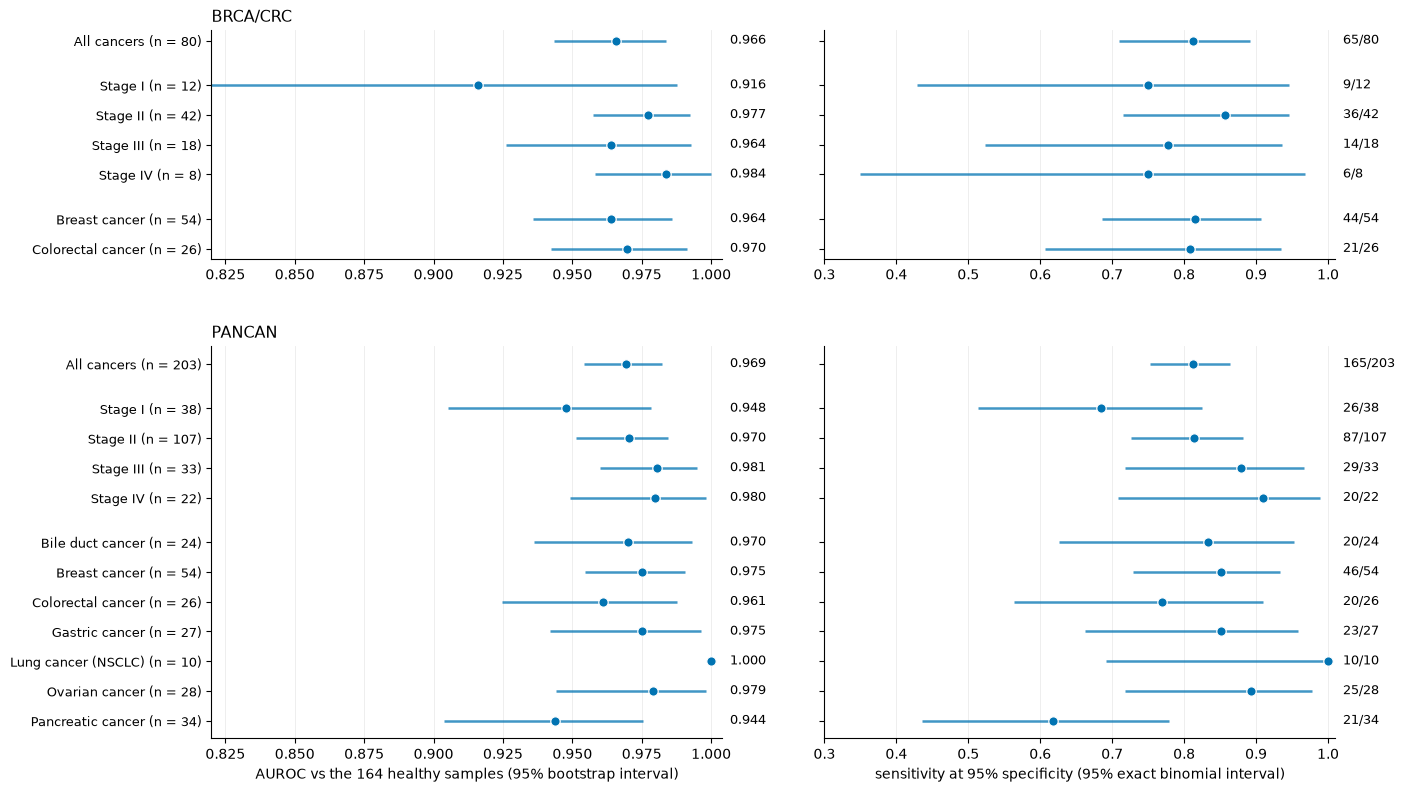

,task,stratum,n_cancer,AUROC [95% CI],sensitivity at 95% specificity [95% CI]
0,BRCA/CRC,All cancers,80,"0.966 [0.943, 0.984]","65/80 = 0.81 [0.71, 0.89]"
1,BRCA/CRC,Stage I,12,"0.916 [0.814, 0.988]","9/12 = 0.75 [0.43, 0.95]"
2,BRCA/CRC,Stage II,42,"0.977 [0.958, 0.992]","36/42 = 0.86 [0.71, 0.95]"
3,BRCA/CRC,Stage III,18,"0.964 [0.926, 0.993]","14/18 = 0.78 [0.52, 0.94]"
4,BRCA/CRC,Stage IV,8,"0.984 [0.958, 1.000]","6/8 = 0.75 [0.35, 0.97]"
5,BRCA/CRC,Breast cancer,54,"0.964 [0.936, 0.986]","44/54 = 0.81 [0.69, 0.91]"
6,BRCA/CRC,Colorectal cancer,26,"0.970 [0.942, 0.991]","21/26 = 0.81 [0.61, 0.93]"
7,PANCAN,All cancers,203,"0.969 [0.954, 0.982]","165/203 = 0.81 [0.75, 0.86]"
8,PANCAN,Stage I,38,"0.948 [0.905, 0.979]","26/38 = 0.68 [0.51, 0.82]"
9,PANCAN,Stage II,107,"0.970 [0.951, 0.985]","87/107 = 0.81 [0.73, 0.88]"


In [6]:
if not all(HAVE_DD.values()):
    print("Section 1h is skipped: the data-driven arm is not exported for this cohort yet")
else:
    # --- 1h: performance by stage and by cancer type, participant-level bootstrap intervals
    from scipy.stats import beta as beta_dist

    def clopper_pearson(k, n, alpha=0.05):
        """Exact binomial interval for k of n."""
        return (0.0 if k == 0 else float(beta_dist.ppf(alpha / 2, k, n - k + 1)),
                1.0 if k == n else float(beta_dist.ppf(1 - alpha / 2, k + 1, n - k)))

    def auc_from_scores(pos, neg):
        r = rankdata(np.concatenate([pos, neg]))
        return (r[:len(pos)].sum() - len(pos) * (len(pos) + 1) / 2) / (len(pos) * len(neg))

    def boot_auc_ci(pos, neg, n_boot=2000, seed=0):
        """Percentile interval; cancers of the stratum and healthy samples resampled separately."""
        rng = np.random.default_rng(seed)
        b = [auc_from_scores(rng.choice(pos, len(pos)), rng.choice(neg, len(neg))) for _ in range(n_boot)]
        return np.percentile(b, [2.5, 97.5])

    STAGES = ["I", "II", "III", "IV"]
    strata_rows = []
    for task in TASKS:
        a = arm(task, "data_driven").merge(scalars[task][["sample_id", "stage", "disease"]], on="sample_id")
        assert len(a) == len(scalars[task])
        a["stage"] = a["stage"].astype(str).str.strip()
        # held-out scores as within-fold percentile ranks, so folds can be pooled
        a["fold_rank"] = a.groupby("fold")["score"].transform(lambda s: rankdata(s) / len(s))
        h = a[a["y_true"] == 0]; ca = a[a["y_true"] == 1]
        spec_k = int((h["score"] < h["threshold_95spec"]).sum()); sp_lo, sp_hi = clopper_pearson(spec_k, len(h))
        print(f"{task}: specificity at the fold-specific train-derived thresholds {spec_k}/{len(h)} = {spec_k / len(h):.3f} "
              f"[{sp_lo:.3f}, {sp_hi:.3f}]; cancers outside stages I-IV: {int((~ca['stage'].isin(STAGES)).sum())} "
              f"({', '.join(sorted(set(ca.loc[~ca['stage'].isin(STAGES), 'stage'])) ) or 'none'})")
        strata = [("All cancers", "all", a["y_true"] == 1)]
        strata += [(f"Stage {s}", "stage", (a["y_true"] == 1) & (a["stage"] == s)) for s in STAGES]
        strata += [(d.replace(" naive nsclc", " (NSCLC)"), "cancer type", (a["y_true"] == 1) & (a["disease"] == d))
                   for d in sorted(ca["disease"].unique())]
        for name, kind, mask in strata:
            c = a[mask]
            lo, hi = boot_auc_ci(c["fold_rank"].to_numpy(), h["fold_rank"].to_numpy())
            k = int((c["score"] >= c["threshold_95spec"]).sum()); s_lo, s_hi = clopper_pearson(k, len(c))
            strata_rows.append({"task": task, "stratum": name, "kind": kind, "n_cancer": len(c), "n_healthy": len(h),
                                "auroc": auc_from_scores(c["fold_rank"].to_numpy(), h["fold_rank"].to_numpy()),
                                "auroc_lo": lo, "auroc_hi": hi, "detected": k, "sensitivity": k / len(c),
                                "sens_lo": s_lo, "sens_hi": s_hi})
    strata_tab = pd.DataFrame(strata_rows)
    strata_tab.to_csv(os.path.join(_DATA, "figS10_by_stage_and_type.csv"), index=False)

    fig, axes = plt.subplots(2, 2, figsize=(14.5, 9.2), gridspec_kw=dict(height_ratios=[7, 12], hspace=0.28, wspace=0.2), sharey="row")
    for r, task in enumerate(TASKS):
        g = strata_tab[strata_tab["task"] == task].iloc[::-1].reset_index(drop=True)
        ypos = np.arange(len(g)) + (g["kind"] == "stage") * 0.5 + (g["kind"] == "all") * 1.0   # small gaps between the groups
        for c_, (val, lo_, hi_, xlab, xlim) in enumerate([
                ("auroc", "auroc_lo", "auroc_hi", f"AUROC vs the {int(g['n_healthy'].iloc[0])} healthy samples (95% bootstrap interval)", (0.82, 1.004)),
                ("sensitivity", "sens_lo", "sens_hi", "sensitivity at 95% specificity (95% exact binomial interval)", (0.3, 1.01))]):
            ax = axes[r, c_]
            ax.hlines(ypos, g[lo_], g[hi_], color=MODEL_COLOR, linewidth=1.8, alpha=0.75)
            ax.scatter(g[val], ypos, s=46, color=MODEL_COLOR, zorder=3, edgecolors="white", linewidths=0.9)
            for yy, row in zip(ypos, g.itertuples()):
                txt = f"{getattr(row, val):.3f}" if val == "auroc" else f"{row.detected}/{row.n_cancer}"
                ax.text(1.015, yy, txt, transform=ax.get_yaxis_transform(), va="center", fontsize=9, clip_on=False)
            ax.set_yticks(ypos); ax.set_yticklabels([f"{row.stratum} (n = {row.n_cancer})" for row in g.itertuples()], fontsize=9.5)
            ax.set_xlim(*xlim); ax.grid(axis="x", alpha=0.25, linewidth=0.6); ax.set_axisbelow(True)
            for side in ("top", "right"):
                ax.spines[side].set_visible(False)
            if r == 1:
                ax.set_xlabel(xlab, fontsize=10)
            if c_ == 0:
                ax.set_title(task, fontsize=11.5, loc="left")
    fig.savefig(out_path("figS10_by_stage_and_type.png"), dpi=300, bbox_inches="tight")
    fig.savefig(out_path("figS10_by_stage_and_type.pdf"), bbox_inches="tight")
    plt.show()

    show_ = strata_tab.assign(**{
        "AUROC [95% CI]": strata_tab.apply(lambda r: f"{r['auroc']:.3f} [{r['auroc_lo']:.3f}, {r['auroc_hi']:.3f}]", axis=1),
        "sensitivity at 95% specificity [95% CI]": strata_tab.apply(
            lambda r: f"{r['detected']}/{r['n_cancer']} = {r['sensitivity']:.2f} [{r['sens_lo']:.2f}, {r['sens_hi']:.2f}]", axis=1)})
    with pd.option_context("display.width", 220, "display.max_rows", 40):
        display(show_[["task", "stratum", "n_cancer", "AUROC [95% CI]", "sensitivity at 95% specificity [95% CI]"]])


Per-type strata are small and not adjusted for stage mix.

## 2. The covariates among themselves

### 2b. How the covariates relate to each other

Spearman correlations between the covariates (pairwise-complete) in four scopes: all samples, healthy,
healthy without the 30 deep-sequenced samples, and cancer.

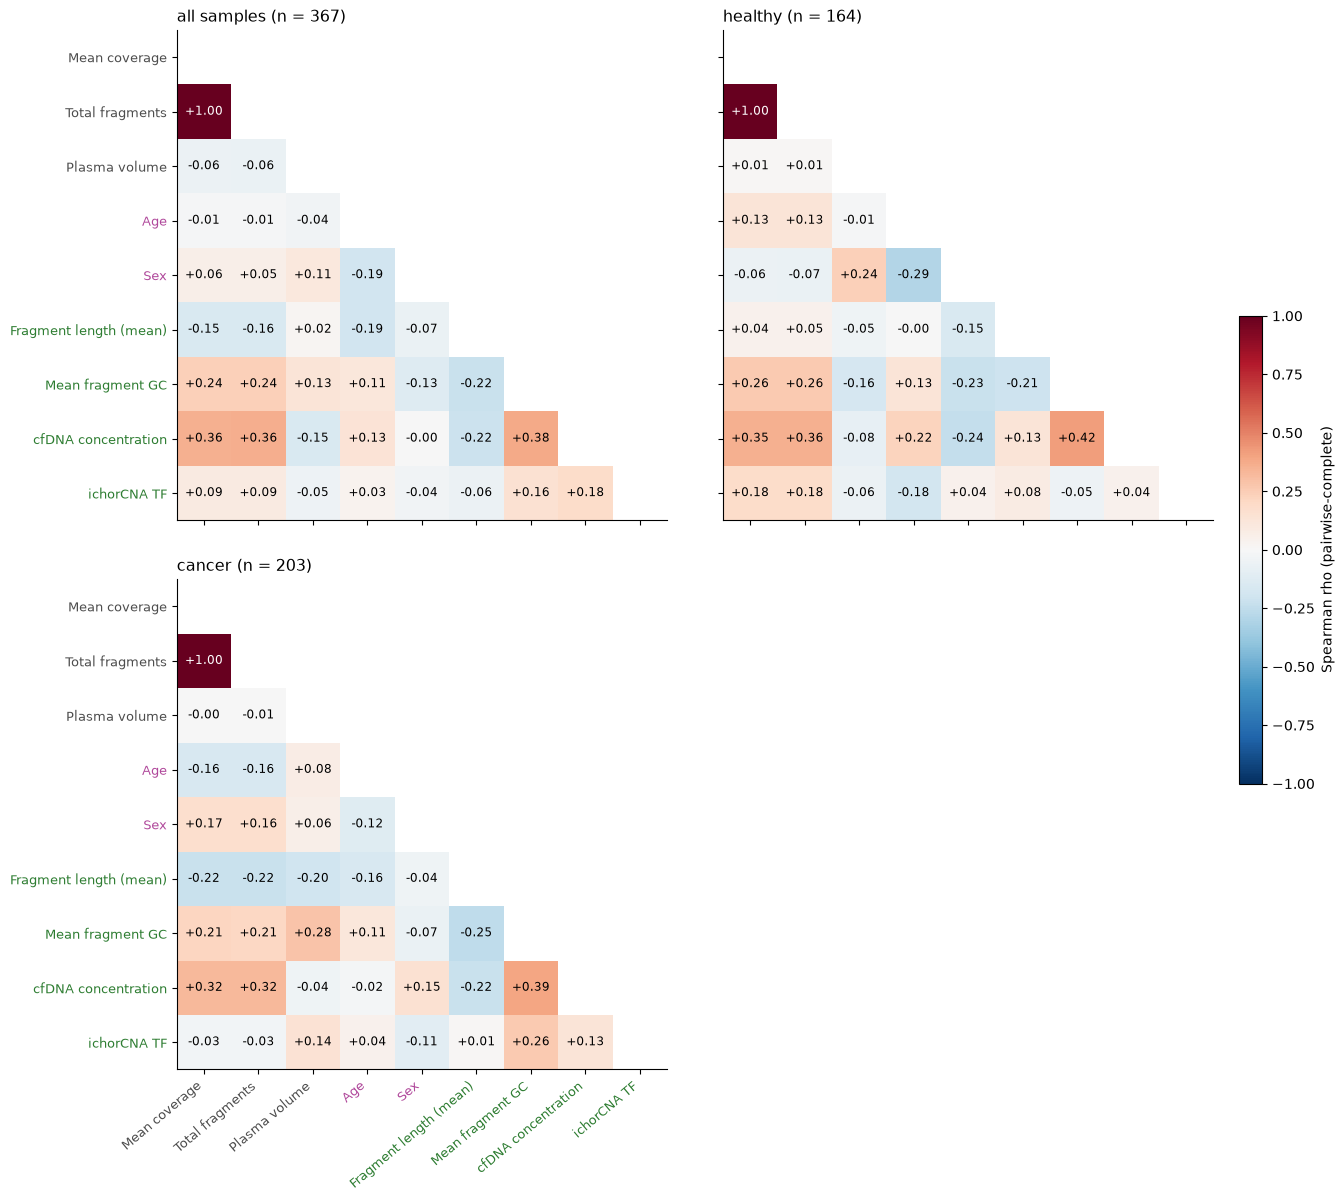

Strongest pairs among the healthy samples (healthy) and among cancers:


,pair,all samples,healthy,cancer
0,Total fragments ~ Mean coverage,1.00,1.00,1.00
1,cfDNA concentration ~ Mean coverage,0.36,0.35,0.32
2,cfDNA concentration ~ Total fragments,0.36,0.36,0.32
3,cfDNA concentration ~ Mean fragment GC,0.38,0.42,0.39


In [7]:
if not all(HAVE_DD.values()):
    print("Section 2b is skipped: the data-driven arm is not exported for this cohort yet")
else:
    # --- 2b: Spearman correlations between the covariates -----------------------------
    if COHORT != "all":
        t = scalars["PANCAN"]   # Section 2 (which defines t) stays skipped under a variant
    deep_t = t["mean_coverage"] > DEEP_COVERAGE_X
    assert deep_t.sum() == N_DEEP_EXPECTED and set(t.loc[deep_t, "sample_id"]) == deep_ids
    COV_SCOPES = [("all samples", pd.Series(True, index=t.index)), ("healthy", t["y_true"] == 0)] + (
        [("healthy, deep-sequenced excluded", (t["y_true"] == 0) & ~deep_t)] if N_DEEP_EXPECTED else []) + [("cancer", t["y_true"] == 1)]
    COVCORR = {name: t.loc[mask, SCALARS].corr(method="spearman") for name, mask in COV_SCOPES}   # pairwise-complete
    fig, axes = plt.subplots(2, 2, figsize=(16.5, 13.5), gridspec_kw=dict(wspace=0.06, hspace=0.12))
    for k_, (ax, (name, mask)) in enumerate(zip(axes.flat, COV_SCOPES)):
        C = COVCORR[name].to_numpy()
        show = np.ma.masked_where(np.triu(np.ones_like(C, bool), k=0), C)   # lower triangle, diagonal left empty
        im = ax.imshow(show, cmap="RdBu_r", vmin=-1, vmax=1)
        for i_ in range(len(C)):
            for j_ in range(i_):
                if np.isfinite(C[i_, j_]):
                    ax.text(j_, i_, f"{C[i_, j_]:+.2f}", ha="center", va="center", fontsize=8.5,
                            color="white" if abs(C[i_, j_]) > 0.55 else "black")
        ax.set_xticks(range(len(SCALARS))); ax.set_yticks(range(len(SCALARS)))
        ax.set_xticklabels([LABELS[c] for c in SCALARS] if k_ >= 2 else [], rotation=40, ha="right", fontsize=9.5)   # shared with the row below
        ax.set_yticklabels([LABELS[c] for c in SCALARS] if k_ % 2 == 0 else [], fontsize=9.5)
        for ticks in (ax.get_xticklabels(), ax.get_yticklabels()):
            for tick, c in zip(ticks, SCALARS):
                tick.set_color(CAT_COLORS[CATEGORIES[c]])
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.set_title(f"{name} (n = {int(mask.sum())})", fontsize=11.5, loc="left")
    for ax in axes.flat[len(COV_SCOPES):]:
        ax.set_visible(False)
    fig.colorbar(im, ax=axes, shrink=0.45, pad=0.02, label="Spearman rho (pairwise-complete)")
    fig.savefig(out_path("figS10_covariate_correlations.png"), dpi=300, bbox_inches="tight")
    fig.savefig(out_path("figS10_covariate_correlations.pdf"), bbox_inches="tight")
    plt.show()
    pd.concat([c.assign(scope=n) for n, c in COVCORR.items()]).to_csv(out_path("figS10_covariate_correlations.csv"))

    # the pairs that move most when the deep-sequenced healthy samples are left out, and the strongest pairs overall
    pairs = []
    for i_, a_ in enumerate(SCALARS):
        for b_ in SCALARS[:i_]:
            pairs.append({"pair": f"{LABELS[a_]} ~ {LABELS[b_]}", **{n: COVCORR[n].loc[a_, b_] for n, _ in COV_SCOPES}})
    pairs = pd.DataFrame(pairs)
    if N_DEEP_EXPECTED:
        pairs["shift"] = (pairs["healthy"] - pairs["healthy, deep-sequenced excluded"]).abs()
        print("Pairs whose within-healthy correlation changes most when the 30 deep-sequenced samples are excluded:")
        display(pairs.sort_values("shift", ascending=False).head(8).drop(columns="shift").round(2).reset_index(drop=True))
        pairs = pairs.drop(columns="shift")
    _hcol = "healthy, deep-sequenced excluded" if N_DEEP_EXPECTED else "healthy"
    print(f"Strongest pairs among the healthy samples ({_hcol}) and among cancers:")
    strong = pairs[(pairs[_hcol].abs() >= 0.35) | (pairs["cancer"].abs() >= 0.35)]
    display(strong.round(2).reset_index(drop=True))


## 3. What the model's score tracks - OOF posteriors vs covariates (exploratory)

Spearman correlations between the pooled participant-level out-of-fold posteriors and every covariate:
pooled (inflated by any covariate that differs between classes) and within class. Cancer stage
(ordinal 0/I-IV; 'X' excluded) enters the cancer-only scope. p-values are BH-adjusted across the full
family per task. OOF scores of one CV replicate are mildly dependent through shared training folds, so
per-fold sign consistency of the significant hits is reported too.

In [8]:
if not all(HAVE_DD.values()):
    print("Section 3 is skipped: the data-driven arm is not exported for this cohort yet")
else:
    STAGE_MAP = {"0": 0.0, "I": 1.0, "II": 2.0, "III": 3.0, "IV": 4.0}
    STAGE_COL = "stage_ordinal"
    SCOPES = ["pooled", "healthy only", "cancer only"]
    posts = {}
    for task in TASKS:
        dd = arm(task, "data_driven")[["sample_id", "score"]].rename(columns={"score": "posterior"})
        m = scalars[task].merge(dd, on="sample_id", how="inner")
        assert len(m) == len(scalars[task]) and m["posterior"].between(0, 1).all()
        m[STAGE_COL] = m["stage"].astype(str).str.strip().map(STAGE_MAP)
        m.loc[m["y_true"] == 0, STAGE_COL] = np.nan
        posts[task] = m
        print(f"{task}: {len(m)} posteriors, staged cancers {int(m[STAGE_COL].notna().sum())}")

    def scope_mask(m, scope):
        if scope == "pooled":
            return pd.Series(True, index=m.index)
        return m["y_true"] == (0 if scope == "healthy only" else 1)

    results = []
    for task, m in posts.items():
        for scope in SCOPES:
            sub = m[scope_mask(m, scope)]
            cols = SCALARS + ([STAGE_COL] if scope == "cancer only" else [])
            for col in cols:
                ok = sub[col].notna()
                rho, p = spearmanr(sub.loc[ok, "posterior"], sub.loc[ok, col])
                results.append({"task": task, "scope": scope, "covariate": col,
                                "category": CATEGORIES.get(col, "clinical"),
                                "n": int(ok.sum()), "rho": rho, "p": p})
    res = pd.DataFrame(results)
    res["q"] = np.nan
    for task in TASKS:
        sel = res["task"] == task
        res.loc[sel, "q"] = false_discovery_control(res.loc[sel, "p"], method="bh")
    res.to_csv(os.path.join(_DATA, "figS10_correlations.csv"), index=False)
    top = res[(res["scope"] != "pooled") & (res["q"] < 0.05)].sort_values("rho", key=abs, ascending=False)
    print(f"\n{len(top)} within-class correlations at BH q < 0.05 "
          f"(of {len(res[res['scope'] != 'pooled'])}):")
    print(top[["task", "scope", "covariate", "n", "rho", "q"]].round(3).to_string(index=False))


BRCA/CRC: 244 posteriors, staged cancers 80
PANCAN: 367 posteriors, staged cancers 202

13 within-class correlations at BH q < 0.05 (of 38):
    task        scope            covariate   n    rho     q
BRCA/CRC  cancer only      cfdna_extracted  80  0.393 0.001
  PANCAN  cancer only      cfdna_extracted 197  0.355 0.000
  PANCAN  cancer only          ichorcna_tf 203  0.351 0.000
BRCA/CRC  cancer only          ichorcna_tf  80  0.329 0.007
BRCA/CRC healthy only              mean_gc 164  0.298 0.001
BRCA/CRC  cancer only        plasma_volume  80 -0.275 0.031
  PANCAN healthy only              mean_gc 164  0.267 0.002
BRCA/CRC healthy only        mean_coverage 164  0.267 0.002
BRCA/CRC healthy only      total_fragments 164  0.267 0.002
  PANCAN healthy only      total_fragments 164  0.246 0.004
  PANCAN healthy only        mean_coverage 164  0.245 0.004
  PANCAN healthy only fragment_length_mean 164 -0.200 0.022
  PANCAN  cancer only              mean_gc 203  0.170 0.030


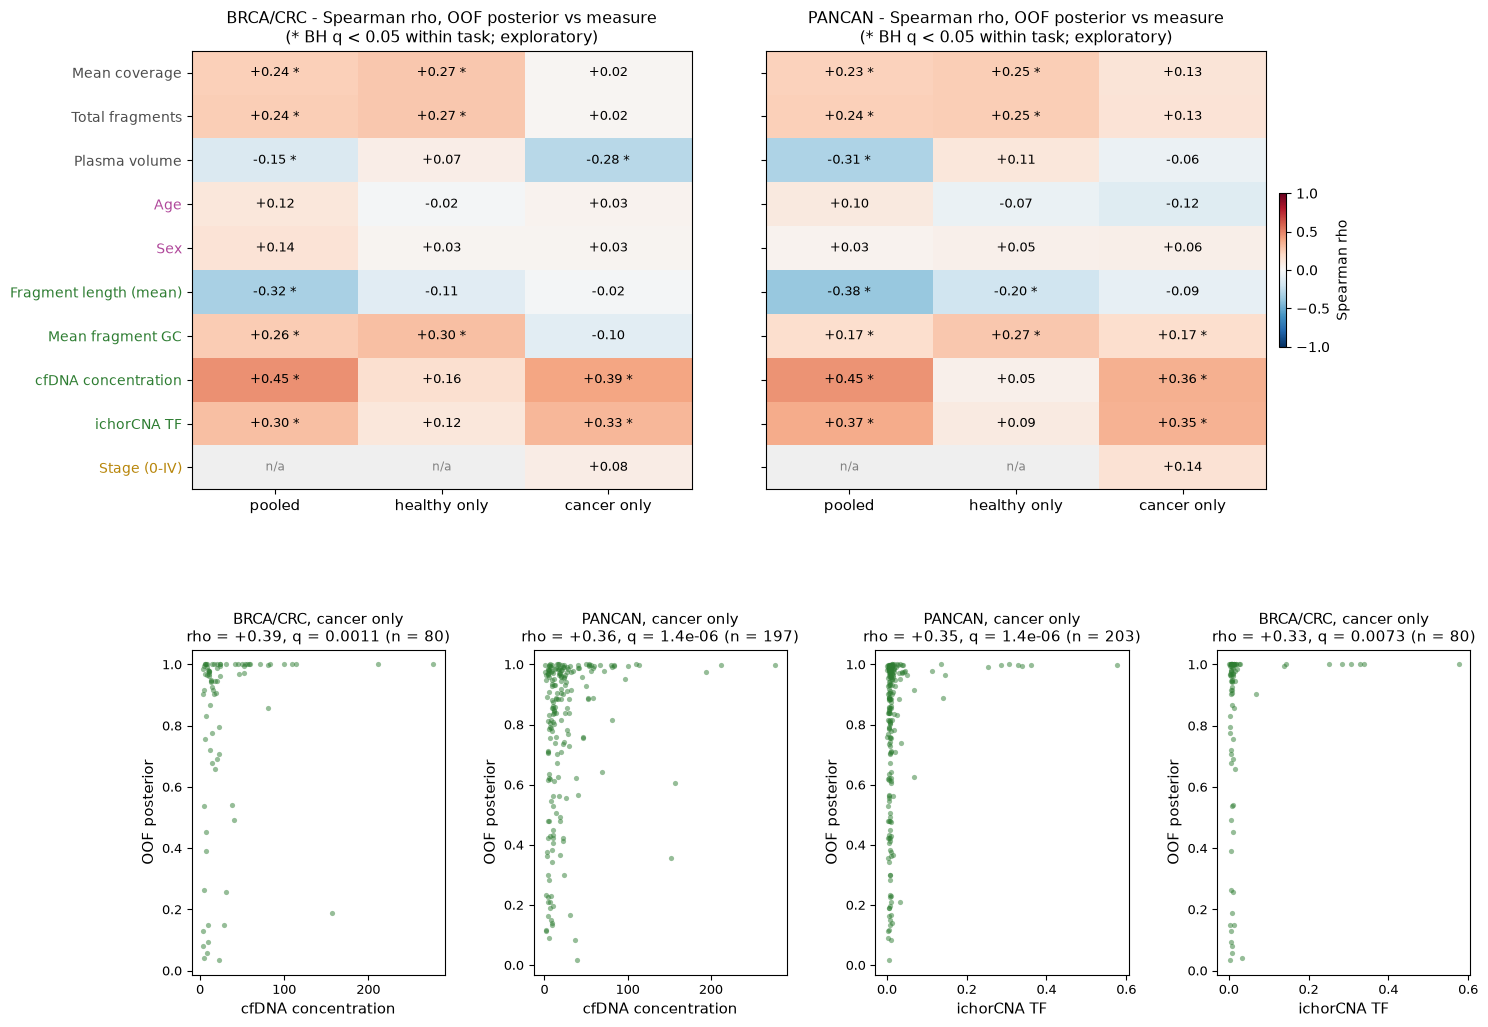

BRCA/CRC  healthy only mean_coverage          rho=+0.27  per-fold median +0.22, 90% of folds same sign
BRCA/CRC  healthy only total_fragments        rho=+0.27  per-fold median +0.22, 90% of folds same sign
BRCA/CRC  healthy only mean_gc                rho=+0.30  per-fold median +0.34, 90% of folds same sign
BRCA/CRC  cancer only  plasma_volume          rho=-0.28  per-fold median -0.23, 70% of folds same sign
BRCA/CRC  cancer only  cfdna_extracted        rho=+0.39  per-fold median +0.52, 80% of folds same sign
BRCA/CRC  cancer only  ichorcna_tf            rho=+0.33  per-fold median +0.36, 90% of folds same sign
PANCAN    healthy only mean_coverage          rho=+0.25  per-fold median +0.19, 80% of folds same sign
PANCAN    healthy only total_fragments        rho=+0.25  per-fold median +0.18, 80% of folds same sign
PANCAN    healthy only fragment_length_mean   rho=-0.20  per-fold median -0.26, 80% of folds same sign
PANCAN    healthy only mean_gc                rho=+0.27  per-fold median 

In [9]:
if not all(HAVE_DD.values()):
    print("Section 3 is skipped: the data-driven arm is not exported for this cohort yet")
else:
    fig = plt.figure(figsize=(16.5, 12))
    gs = fig.add_gridspec(2, 4, height_ratios=[1.35, 1], hspace=0.42, wspace=0.35)
    covs = SCALARS + [STAGE_COL]
    cov_cat = dict(CATEGORIES, **{STAGE_COL: "clinical"})
    cov_label = dict(LABELS, **{STAGE_COL: "Stage (0-IV)"})
    cmap = plt.get_cmap("RdBu_r").copy(); cmap.set_bad("#EFEFEF")
    for j, task in enumerate(TASKS):
        ax = fig.add_subplot(gs[0, 2 * j:2 * j + 2])
        mat = np.full((len(covs), len(SCOPES)), np.nan); qmat = np.ones_like(mat)
        for si, scope in enumerate(SCOPES):
            for ci, col in enumerate(covs):
                row = res[(res["task"] == task) & (res["scope"] == scope) & (res["covariate"] == col)]
                if len(row):
                    mat[ci, si] = row["rho"].iloc[0]; qmat[ci, si] = row["q"].iloc[0]
        im = ax.imshow(np.ma.masked_invalid(mat), cmap=cmap, vmin=-1, vmax=1, aspect="auto")
        for ci in range(len(covs)):
            for si in range(len(SCOPES)):
                if np.isnan(mat[ci, si]):
                    ax.text(si, ci, "n/a", ha="center", va="center", fontsize=8.5, color="gray"); continue
                star = " *" if qmat[ci, si] < 0.05 else ""
                ax.text(si, ci, f"{mat[ci, si]:+.2f}{star}", ha="center", va="center", fontsize=9.5,
                        color="white" if abs(mat[ci, si]) > 0.55 else "black")
        ax.set_xticks(range(len(SCOPES))); ax.set_xticklabels(SCOPES, fontsize=10.5)
        ax.set_yticks(range(len(covs)))
        if j == 0:
            ax.set_yticklabels([cov_label[c] for c in covs], fontsize=10)
            for tick, c in zip(ax.get_yticklabels(), covs):
                tick.set_color(CAT_COLORS[cov_cat[c]])
        else:
            ax.set_yticklabels([])
        ax.set_title(f"{task} - Spearman rho, OOF posterior vs measure\n(* BH q < 0.05 within task; exploratory)", fontsize=11.5)
    fig.colorbar(im, ax=fig.axes, shrink=0.35, pad=0.01, label="Spearman rho")
    picks = (res[res["scope"] != "pooled"].sort_values("rho", key=abs, ascending=False)
             .groupby("task", sort=False).head(2).reset_index(drop=True))
    for k, row in picks.iterrows():
        ax = fig.add_subplot(gs[1, k])
        m = posts[row["task"]]
        sub = m[scope_mask(m, row["scope"]) & m[row["covariate"]].notna()]
        ax.scatter(sub[row["covariate"]], sub["posterior"], s=14, alpha=0.5,
                   color=CAT_COLORS[row["category"]], linewidths=0)
        ax.set_xlabel(cov_label[row["covariate"]], fontsize=10.5); ax.set_ylabel("OOF posterior", fontsize=10.5)
        ax.set_title(f"{row['task']}, {row['scope']}\nrho = {row['rho']:+.2f}, q = {row['q']:.2g} (n = {row['n']})", fontsize=10.5)
        ax.tick_params(labelsize=9)
    fig.savefig(out_path("figS10_correlations.png"), dpi=300, bbox_inches="tight")
    fig.savefig(out_path("figS10_correlations.pdf"), bbox_inches="tight")
    plt.show()

    sig = res[(res["scope"] != "pooled") & (res["q"] < 0.05)]
    for _, row in sig.iterrows():
        m = posts[row["task"]]
        sub = m[scope_mask(m, row["scope"]) & m[row["covariate"]].notna()]
        per_fold = [spearmanr(g["posterior"], g[row["covariate"]])[0] for _, g in sub.groupby("fold") if len(g) >= 5]
        frac_same = np.mean([np.sign(r) == np.sign(row["rho"]) for r in per_fold])
        print(f"{row['task']:9s} {row['scope']:12s} {row['covariate']:22s} rho={row['rho']:+.2f}  "
              f"per-fold median {np.median(per_fold):+.2f}, {frac_same:.0%} of folds same sign")
    for task in TASKS:
        r = res[(res["task"] == task) & (res["scope"] == "pooled") & (res["covariate"] == "fragment_length_mean")]["rho"].iloc[0]
        assert COHORT != "all" or r < -0.3, task   # pinned on the full cohort
        rs = res[(res["task"] == task) & (res["scope"] == "cancer only") & (res["covariate"] == STAGE_COL)]
        print(f"{task}: posterior~stage within cancers rho = {rs['rho'].iloc[0]:+.2f} (q = {rs['q'].iloc[0]:.2g}, n = {rs['n'].iloc[0]})")
        assert COHORT != "all" or rs["rho"].iloc[0] > 0, task   # pinned on the full cohort
    print("\nchecks " + ("passed" if COHORT == "all" else "printed (pins apply to the full cohort only)")
          + ": pooled posterior vs fragment length (expected negative) and vs stage within cancers (expected positive)")


<!-- assembled-figure -->
## 6. Figure S10 (assembled)

Drawn from the objects computed in Sections 1, 1g, 1h, 2b and 3. The single-covariate bars show the nine
reported covariates and the panels listed in `FIG_PANELS` below. Panels c and d describe the deep-sequenced
subgroup, which the no_deep cohort excludes; they read two full-cohort files whatever the cohort switch:
`data/figS10_depth_subgroup.csv` (`export/export_figS10_subgroup.py`) and `data/figS8_predictions.csv` (the uniform-depth runs
of Fig S8 on the full cohort). Output: `figS10.png` / `.pdf` in the cohort's output folder.

| panel | content | section |
|---|---|---|
| a, b | AUROC of every single covariate, every covariate panel and the TSS model, per task | 1 |
| c | the deep-sequenced subgroup: depth by group | - |
| d | its within-healthy rank under the full-depth and the uniform-depth runs | Fig S8 |
| e | Spearman correlation of the held-out posterior with each covariate, within class | 3 |
| f | correlations between the covariates within the healthy donors | 2b |
| g | rank agreement of the TSS model with each covariate panel, within class | 1g |
| h-k | AUROC and sensitivity at 95 % specificity by stage and cancer type, with intervals | 1h |
| l | AUROC in samples with shorter and longer fragments than the healthy-donor median: BRCA/CRC and pan-cancer (Cristiano), the Cristiano model applied to Jiang, and the model trained within Jiang (bootstrap p-value of the difference in the CSV only) | 6 |
| m-p | posterior (log-odds) against mean fragment length, per cohort (Cristiano pan-cancer; Cristiano model applied to Jiang) and class; black line = the panel's least-squares fit, slope per 5 bp with HC3 95% CI; Jiang panels: p for the slope differing from the Cristiano panel of the same class; Spearman per panel | 6 |

                           cohort    half  cut_bp  n_cancer  n_control  auroc    lo    hi  auroc_diff_longer_minus_shorter  p_bootstrap
              Cristiano, BRCA/CRC shorter  165.75        60         82  0.957 0.926 0.982                            0.003        0.838
              Cristiano, BRCA/CRC  longer  165.75        20         82  0.961 0.904 0.998                            0.003        0.838
                Cristiano, PANCAN shorter  165.75       153         82  0.962 0.939 0.980                            0.003        0.821
                Cristiano, PANCAN  longer  165.75        50         82  0.964 0.928 0.991                            0.003        0.821
Jiang, model trained on Cristiano shorter  169.79        39         68  0.793 0.710 0.875                           -0.077        0.232
Jiang, model trained on Cristiano  longer  169.79        51         67  0.713 0.624 0.809                           -0.077        0.232
Jiang, model trained within Jiang shorter  169.7

               cohort     cls   n  spearman     p  slope_per_5bp  slope_lo  slope_hi  p_slope_vs_cristiano
Cristiano, pan-cancer healthy 164    -0.200 0.010         -0.907    -1.659    -0.155                   NaN
Cristiano, pan-cancer  cancer 203    -0.086 0.220         -0.092    -0.908     0.725                   NaN
                Jiang non-HCC 135    -0.212 0.014         -0.577    -1.321     0.166                 0.542
                Jiang     HCC  90    -0.304 0.004         -0.812    -1.284    -0.340                 0.134


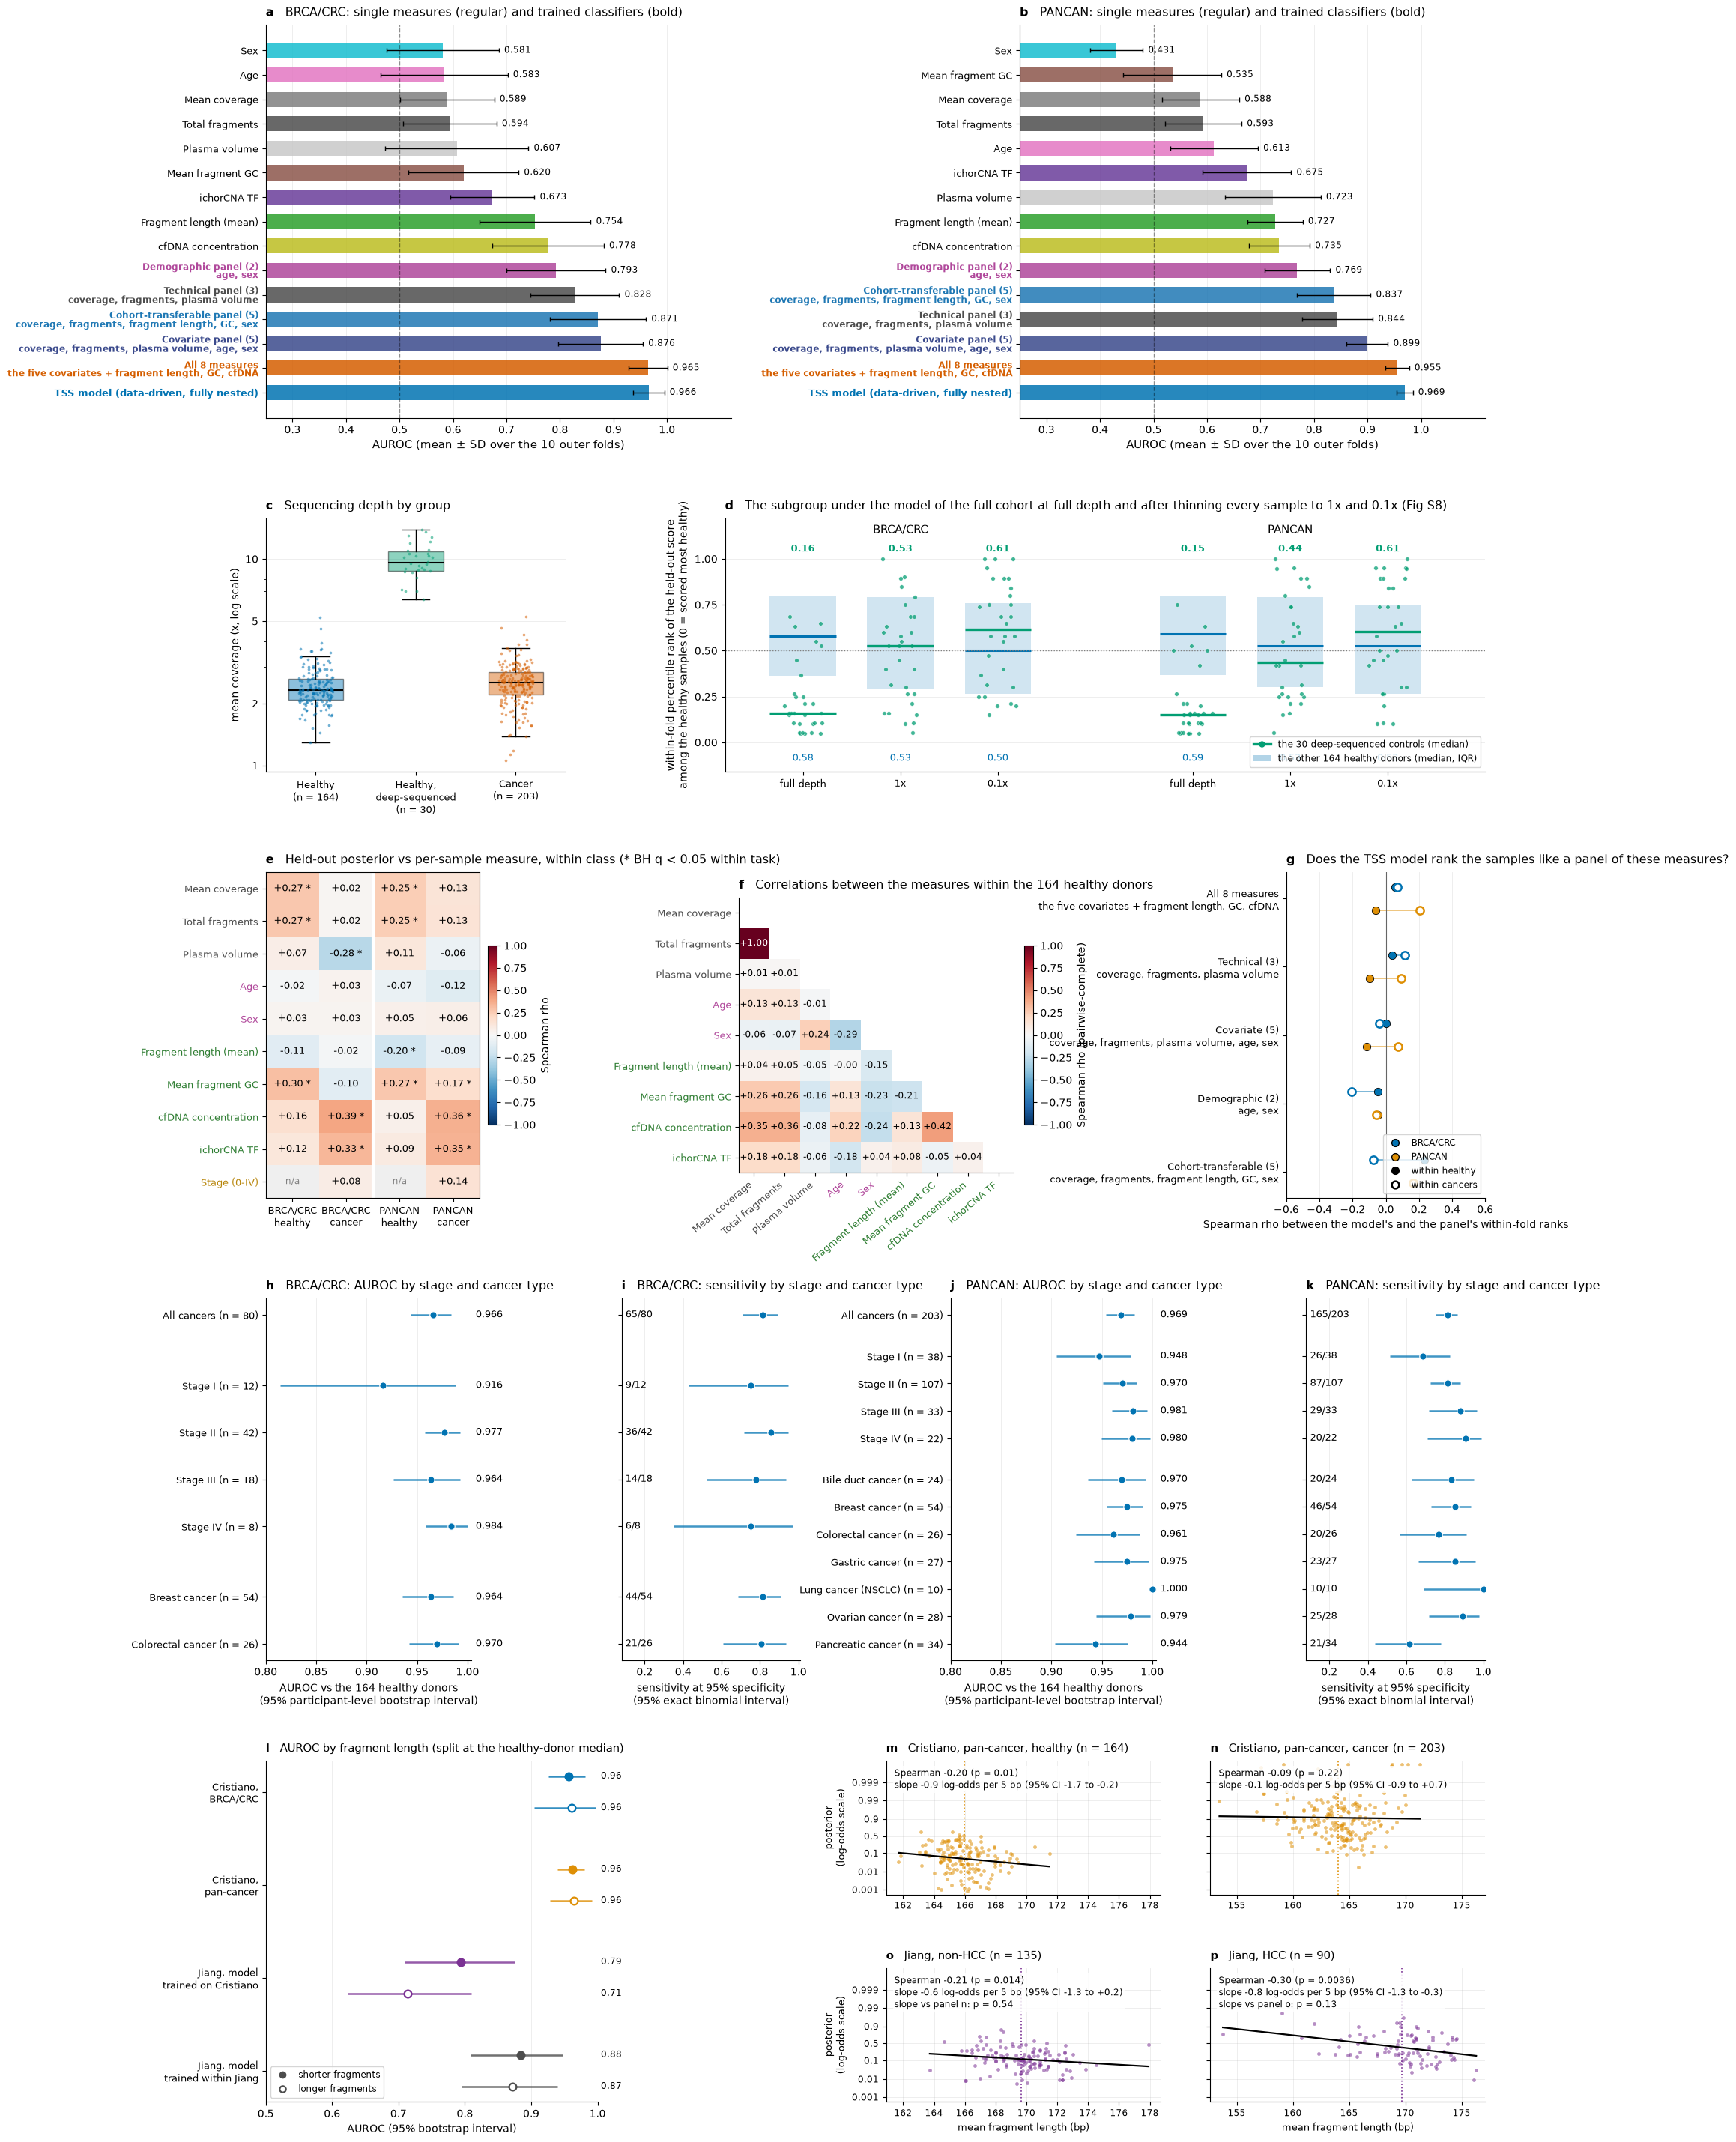

Figure S10 written to output\no_deep\figS10.png and .pdf


In [10]:
if not all(HAVE_DD.values()):
    print("Figure S10 is not assembled: the data-driven arm is not exported for this cohort yet")
else:
    # --- what the figure reports -----------------------------------------------------------
    FIG_COVS = list(SCALARS)  # the nine reported covariates
    # the cohort-transferable panel (coverage, fragments, fragment length, GC, sex from the BAM) is the set
    # deployed on Jiang in Fig S16
    FIG_PANELS = ["bl_panel_technical3", "bl_panel_demographic", "bl_panel_transfer5", "bl_panel_techdemo5", "bl_panel_all8"]
    # each panel label carries its composition on a second line (bold tick labels are coloured like their bars)
    FIG_PANEL_LABEL = {"bl_panel_technical3": "Technical panel (3)\ncoverage, fragments, plasma volume",
                       "bl_panel_demographic": "Demographic panel (2)\nage, sex",
                       "bl_panel_transfer5": "Cohort-transferable panel (5)\ncoverage, fragments, fragment length, GC, sex",
                       "bl_panel_techdemo5": "Covariate panel (5)\ncoverage, fragments, plasma volume, age, sex",
                       "bl_panel_all8": "All 8 measures\nthe five covariates + fragment length, GC, cfDNA"}
    for task in TASKS:
        for p in FIG_PANELS:
            if not (arms[task]["method"] == p).any():
                print(f"NOTE: {task}: panel {p} is not in the exported arms yet (run its nested-CV job and export_fig3_baselines.py); it is left out of panels a, b and h")
    TASK_COL = {"BRCA/CRC": "#0173B2", "PANCAN": "#DE8F05"}
    G3 = ["Healthy", "Healthy,\ndeep-sequenced", "Cancer"]
    G3C = {"Healthy": "#0173B2", "Healthy,\ndeep-sequenced": "#029E73", "Cancer": "#D55E00"}

    def ttl(ax, letter, text, size=11.5):
        ax.set_title(f"$\\bf{{{letter}}}$   {text}", loc="left", fontsize=size, pad=8)

    def clean(ax):
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        ax.set_axisbelow(True)

    # full-cohort files that describe the subgroup (identical under every cohort switch)
    dsub_all = pd.read_csv(os.path.join("data", "figS10_depth_subgroup.csv"))
    assert len(dsub_all) == 397 and int(dsub_all["deep_subgroup"].sum()) == 30
    dsub_all["group"] = np.where(dsub_all["y_true"] == 1, "Cancer", np.where(dsub_all["deep_subgroup"], "Healthy,\ndeep-sequenced", "Healthy"))
    deep30 = set(dsub_all.loc[dsub_all["deep_subgroup"], "sample_id"])
    s8 = pd.read_csv(os.path.join("data", "figS8_predictions.csv"))
    h8 = s8[(s8["y_true"] == 0) & s8["depth"].isin(["full", "cov1x", "cov0.1x"])].copy()
    h8["deep"] = h8["sample_id"].isin(deep30)
    assert h8.groupby(["task", "depth"])["deep"].sum().eq(30).all(), "Fig S8 file is not the manuscript-cohort export"
    h8["rank"] = h8.groupby(["task", "depth", "fold"])["score"].rank(pct=True)   # within-fold percentile rank among the healthy samples of the test fold

    fig = plt.figure(figsize=(21, 36))
    gs = fig.add_gridspec(5, 1, height_ratios=[7.6, 4.9, 6.3, 7.0, 6.6], hspace=0.30)
    g0 = gs[0].subgridspec(1, 2, wspace=0.62)
    g1 = gs[1].subgridspec(1, 2, width_ratios=[0.75, 1.9], wspace=0.30)
    g2 = gs[2].subgridspec(1, 3, width_ratios=[1.05, 1.35, 0.8], wspace=0.8)
    g3 = gs[3].subgridspec(1, 4, width_ratios=[1.15, 1.0, 1.15, 1.0], wspace=0.78)

    # --- a, b: AUROC by approach -------------------------------------------------------------
    for j, task in enumerate(TASKS):
        ax = fig.add_subplot(g0[0, j]); a = arms[task]
        rows = []
        for m in [f"bl_{c}" for c in FIG_COVS] + [p for p in FIG_PANELS if (a["method"] == p).any()] + ["data_driven"]:
            aucs = np.array([x[2] for x in fold_rocs(arm(task, m))])
            if m == "data_driven":
                label, color, bold = "TSS model (data-driven, fully nested)", MODEL_COLOR, True
            elif m in PANELS:
                label, color, bold = FIG_PANEL_LABEL[m], PANELS[m]["color"], True
            else:
                label, color, bold = LABELS[m[3:]], SCALAR_COLORS[m[3:]], False
            rows.append((label, aucs.mean(), aucs.std(), color, bold))
        rows.sort(key=lambda t: t[1], reverse=True)   # strongest at the bottom: the gradient reads downward
        ypos = np.arange(len(rows))
        ax.barh(ypos, [t[1] for t in rows], xerr=[t[2] for t in rows], color=[t[3] for t in rows], alpha=0.85,
                height=0.62, error_kw={"elinewidth": 1.0, "capsize": 2.2})
        ax.set_yticks(ypos); ax.set_yticklabels([t[0] for t in rows], fontsize=9.5)
        for tick, t in zip(ax.get_yticklabels(), rows):
            if t[4]:
                tick.set_fontweight("bold"); tick.set_color(t[3])
            if "\n" in t[0]:                      # panel name + its composition
                tick.set_fontsize(8.8); tick.set_linespacing(1.0)
        for t, y0 in zip(rows, ypos):
            ax.text(t[1] + t[2] + 0.01, y0, f"{t[1]:.3f}", va="center", fontsize=8.5)
        ax.axvline(0.5, color="k", linestyle="--", alpha=0.4, linewidth=1.0)
        ax.set_xlim(0.25, 1.12); ax.set_xticks(np.arange(0.3, 1.01, 0.1))
        ax.set_xlabel("AUROC (mean ± SD over the 10 outer folds)", fontsize=10.5)
        ax.grid(axis="x", alpha=0.25, linewidth=0.6); clean(ax)
        ttl(ax, "ab"[j], f"{task}: single measures (regular) and trained classifiers (bold)")

    # --- c: depth of the deep-sequenced subgroup ---------------------------------------------
    for j, (col, ylab, logy) in enumerate([("mean_coverage", "mean coverage (x, log scale)", True)]):
        ax = fig.add_subplot(g1[0, j])
        data = [dsub_all.loc[dsub_all["group"] == g, col].to_numpy() for g in G3]
        bp = ax.boxplot(data, positions=range(3), widths=0.55, showfliers=False, patch_artist=True,
                        medianprops=dict(color="black", linewidth=1.5))
        for patch, g in zip(bp["boxes"], G3):
            patch.set_facecolor(G3C[g]); patch.set_alpha(0.45)
        rng = np.random.default_rng(0)
        for i_, (v, g) in enumerate(zip(data, G3)):
            ax.scatter(i_ + rng.uniform(-0.17, 0.17, len(v)), v, s=7, color=G3C[g], alpha=0.55, linewidths=0, zorder=3)
        if logy:
            ax.set_yscale("log"); ax.set_yticks([1, 2, 5, 10]); ax.set_yticklabels(["1", "2", "5", "10"])
        ax.set_xticks(range(3)); ax.set_xticklabels([f"{g}\n(n = {len(v)})" for g, v in zip(G3, data)], fontsize=9)
        ax.set_ylabel(ylab, fontsize=10); ax.grid(axis="y", alpha=0.25, linewidth=0.6); clean(ax)
        ttl(ax, "c", "Sequencing depth by group")

    # --- d: their within-healthy rank at full depth and under the uniform-depth runs ----------
    ax = fig.add_subplot(g1[0, 1])
    DEPTHS = [("full", "full depth"), ("cov1x", "1x"), ("cov0.1x", "0.1x")]
    rng = np.random.default_rng(1); ticks, tlabs = [], []
    for ti, (task8, tl8) in enumerate([("brca_crc", "BRCA/CRC"), ("pancan", "PANCAN")]):
        for di, (dep, dl) in enumerate(DEPTHS):
            g = h8[(h8["task"] == task8) & (h8["depth"] == dep)]
            x = ti * 4 + di
            o = g.loc[~g["deep"], "rank"]; d_ = g.loc[g["deep"], "rank"]
            ax.add_patch(plt.Rectangle((x - 0.34, o.quantile(0.25)), 0.68, o.quantile(0.75) - o.quantile(0.25),
                                       facecolor="#0173B2", alpha=0.18, linewidth=0))
            ax.hlines(o.median(), x - 0.34, x + 0.34, color="#0173B2", linewidth=2.2)
            ax.scatter(x + rng.uniform(-0.2, 0.2, len(d_)), d_, s=16, color="#029E73", alpha=0.75, edgecolors="white", linewidths=0.4, zorder=3)
            ax.hlines(d_.median(), x - 0.34, x + 0.34, color="#029E73", linewidth=2.4, zorder=4)
            ax.text(x, 1.04, f"{d_.median():.2f}", ha="center", fontsize=9, color="#029E73", fontweight="bold")
            ax.text(x, -0.1, f"{o.median():.2f}", ha="center", fontsize=9, color="#0173B2")
            ticks.append(x); tlabs.append(dl)
        ax.text(ti * 4 + 1, 1.14, tl8, ha="center", fontsize=11)
    ax.set_xticks(ticks); ax.set_xticklabels(tlabs, fontsize=9.5); ax.set_xlim(-0.8, 7.0)
    ax.axhline(0.5, color="0.5", linestyle=":", linewidth=1); ax.set_ylim(-0.16, 1.22)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_ylabel("within-fold percentile rank of the held-out score\namong the healthy samples (0 = scored most healthy)", fontsize=10)
    ax.legend(handles=[Line2D([], [], marker="o", color="#029E73", linestyle="-", linewidth=2.4, markersize=5, label="the 30 deep-sequenced controls (median)"),
                       Patch(facecolor="#0173B2", alpha=0.3, label="the other 164 healthy donors (median, IQR)")],
              loc="lower right", fontsize=8.5, frameon=True)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6); clean(ax)
    ttl(ax, "d", "The subgroup under the model of the full cohort at full depth and after thinning every sample to 1x and 0.1x (Fig S8)")

    # --- e: posterior vs covariate within class ----------------------------------------------
    ax = fig.add_subplot(g2[0, 0])
    covs_f = FIG_COVS + [STAGE_COL]
    cols_f = [(task, scope) for task in TASKS for scope in ["healthy only", "cancer only"]]
    mat = np.full((len(covs_f), len(cols_f)), np.nan); qm = np.ones_like(mat)
    for si, (task, scope) in enumerate(cols_f):
        for ci, col in enumerate(covs_f):
            row = res[(res["task"] == task) & (res["scope"] == scope) & (res["covariate"] == col)]
            if len(row):
                mat[ci, si] = row["rho"].iloc[0]; qm[ci, si] = row["q"].iloc[0]
    cmap_f = plt.get_cmap("RdBu_r").copy(); cmap_f.set_bad("#EFEFEF")
    im = ax.imshow(np.ma.masked_invalid(mat), cmap=cmap_f, vmin=-1, vmax=1, aspect="auto")
    for ci in range(len(covs_f)):
        for si in range(len(cols_f)):
            if np.isnan(mat[ci, si]):
                ax.text(si, ci, "n/a", ha="center", va="center", fontsize=8.5, color="gray"); continue
            ax.text(si, ci, f"{mat[ci, si]:+.2f}{' *' if qm[ci, si] < 0.05 else ''}", ha="center", va="center", fontsize=9.5,
                    color="white" if abs(mat[ci, si]) > 0.55 else "black")
    ax.set_xticks(range(len(cols_f))); ax.set_xticklabels([f"{t}\n{s.replace(' only', '')}" for t, s in cols_f], fontsize=9.5)
    ax.set_yticks(range(len(covs_f))); ax.set_yticklabels([dict(LABELS, **{STAGE_COL: "Stage (0-IV)"})[c] for c in covs_f], fontsize=9.5)
    for tick, c in zip(ax.get_yticklabels(), covs_f):
        tick.set_color(CAT_COLORS[CATEGORIES.get(c, "clinical")])
    ax.axvline(1.5, color="white", linewidth=3)
    fig.colorbar(im, ax=ax, shrink=0.55, pad=0.03, label="Spearman rho")
    ttl(ax, "e", "Held-out posterior vs per-sample measure, within class (* BH q < 0.05 within task)")

    # --- f: the covariates among the healthy donors ------------------------------------------
    ax = fig.add_subplot(g2[0, 1])
    C = COVCORR["healthy"].loc[FIG_COVS, FIG_COVS].to_numpy()
    show = np.ma.masked_where(np.triu(np.ones_like(C, bool), k=0), C)
    im = ax.imshow(show, cmap="RdBu_r", vmin=-1, vmax=1)
    for i_ in range(len(C)):
        for j_ in range(i_):
            if np.isfinite(C[i_, j_]):
                ax.text(j_, i_, f"{C[i_, j_]:+.2f}", ha="center", va="center", fontsize=8.5, color="white" if abs(C[i_, j_]) > 0.55 else "black")
    ax.set_xticks(range(len(FIG_COVS))); ax.set_yticks(range(len(FIG_COVS)))
    ax.set_xticklabels([LABELS[c] for c in FIG_COVS], rotation=40, ha="right", fontsize=9.5)
    ax.set_yticklabels([LABELS[c] for c in FIG_COVS], fontsize=9.5)
    for ticks in (ax.get_xticklabels(), ax.get_yticklabels()):
        for tick, c in zip(ticks, FIG_COVS):
            tick.set_color(CAT_COLORS[CATEGORIES[c]])
    clean(ax)
    fig.colorbar(im, ax=ax, shrink=0.55, pad=0.03, label="Spearman rho (pairwise-complete)")
    n_h = int((scalars["PANCAN"]["y_true"] == 0).sum())
    ttl(ax, "f", f"Correlations between the measures within the {n_h} healthy donors")

    # --- g: rank agreement of the model with each panel, within class -------------------------
    ax = fig.add_subplot(g2[0, 2])
    panels_h = [m for m in TRAINED[1:] if m in FIG_PANELS]
    ylabs = []
    for yi, m in enumerate(panels_h):
        for task in TASKS:
            r = sim[(sim["task"] == task) & (sim["panel"] == TR_LABEL[m])]
            if r.empty:
                continue
            off = -0.17 if task == "BRCA/CRC" else 0.17
            ax.plot([r["healthy"].iloc[0], r["cancer"].iloc[0]], [yi + off] * 2, color=TASK_COL[task], linewidth=1.2, alpha=0.6, zorder=1)
            ax.scatter(r["healthy"].iloc[0], yi + off, s=55, color=TASK_COL[task], edgecolors="black", linewidths=0.6, zorder=3)
            ax.scatter(r["cancer"].iloc[0], yi + off, s=55, facecolors="white", edgecolors=TASK_COL[task], linewidths=1.8, zorder=3)
        ylabs.append(FIG_PANEL_LABEL[m].replace(" panel", "").replace(": technical + demographic", "").replace("Pipeline + demographic", "Pipeline +\ndemographic"))
    ax.set_yticks(range(len(panels_h))); ax.set_yticklabels(ylabs, fontsize=9.5); ax.invert_yaxis()
    ax.axvline(0, color="0.4", linewidth=0.8); ax.set_xlim(-0.6, 0.6)
    ax.set_xlabel("Spearman rho between the model's and the panel's within-fold ranks", fontsize=10)
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor=TASK_COL[t], markeredgecolor="black", markersize=7, label=t) for t in TASKS]
              + [Line2D([], [], marker="o", linestyle="", markerfacecolor="black", markeredgecolor="black", markersize=7, label="within healthy"),
                 Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="black", markeredgewidth=1.8, markersize=7, label="within cancers")],
              loc="lower right", fontsize=8.5, frameon=True)
    ax.grid(axis="x", alpha=0.25, linewidth=0.6); clean(ax)
    ttl(ax, "g", "Does the TSS model rank the samples like a panel of these measures?")

    # --- h-k: by stage and cancer type -------------------------------------------------------
    for j, task in enumerate(TASKS):
        g = strata_tab[strata_tab["task"] == task].iloc[::-1].reset_index(drop=True)
        ypos = np.arange(len(g)) + (g["kind"] == "stage") * 0.5 + (g["kind"] == "all") * 1.0
        for c_, (val, lo_, hi_, xlab, xlim) in enumerate([
                ("auroc", "auroc_lo", "auroc_hi", f"AUROC vs the {int(g['n_healthy'].iloc[0])} healthy donors\n(95% participant-level bootstrap interval)", (0.8, 1.004)),
                ("sensitivity", "sens_lo", "sens_hi", "sensitivity at 95% specificity\n(95% exact binomial interval)", (0.08, 1.01))]):
            ax = fig.add_subplot(g3[0, 2 * j + c_])
            ax.hlines(ypos, g[lo_], g[hi_], color=MODEL_COLOR, linewidth=1.8, alpha=0.75)
            ax.scatter(g[val], ypos, s=46, color=MODEL_COLOR, zorder=3, edgecolors="white", linewidths=0.9)
            for yy, row in zip(ypos, g.itertuples()):
                if val == "auroc":   # AUROC: value to the right of the axis (the sensitivity panel next to it has no tick labels)
                    ax.text(1.02, yy, f"{row.auroc:.3f}", transform=ax.get_yaxis_transform(), va="center", fontsize=9, clip_on=False)
                else:                # sensitivity: detected / n at the left edge, inside the axis
                    ax.text(0.1, yy, f"{row.detected}/{row.n_cancer}", va="center", ha="left", fontsize=9)
            ax.set_yticks(ypos); ax.set_yticklabels([f"{row.stratum} (n = {row.n_cancer})" for row in g.itertuples()] if c_ == 0 else [], fontsize=9.5)
            ax.set_xlim(*xlim); ax.set_xlabel(xlab, fontsize=10); ax.grid(axis="x", alpha=0.25, linewidth=0.6); clean(ax)
            ttl(ax, "hijk"[2 * j + c_], f"{task}: {'AUROC' if c_ == 0 else 'sensitivity'} by stage and cancer type")

    # --- m, n: fragment length and the model's score ----------------------------------------
    # m: AUROC in the samples with shorter and longer fragments than the cohort's healthy-donor median.
    # n: the score (logit) against fragment length centred within each cohort, OLS of
    # logit ~ class + fragment length x cohort (HC3 robust errors).
    g4 = gs[4].subgridspec(1, 2, width_ratios=[0.72, 1.3], wspace=0.62)
    jsc = pd.read_csv(data_path("figS16_jiang_scores.csv"))[["sample_id", "y_true", "tss"]].rename(columns={"tss": "score"})
    jfl = pd.read_csv(data_path("figS10_jiang_scalars.csv"))[["sample_id", "fragment_length_mean"]]
    FL = {}
    for task in TASKS:
        d = arm(task, "data_driven")[["sample_id", "y_true", "score"]]
        assert d["sample_id"].is_unique, task
        d = d.merge(scalars[task][["sample_id", "fragment_length_mean"]], on="sample_id")
        assert len(d) == len(scalars[task]), task
        FL[f"Cristiano, {task}"] = d
    FL["Jiang, model trained on Cristiano"] = jsc.merge(jfl, on="sample_id")
    assert len(FL["Jiang, model trained on Cristiano"]) == 225
    # the same procedure trained and evaluated within Jiang (nested CV, out-of-fold scores; Fig 5 / S12)
    jin = pd.read_csv(data_path("fig4gi_jiang_nested_oof.csv"))
    jin = jin[jin["task"] == "hcc_vs_nonhcc"][["sample_id", "y_true", "score"]]
    FL["Jiang, model trained within Jiang"] = jin.merge(jfl, on="sample_id")
    assert len(FL["Jiang, model trained within Jiang"]) == 225
    FL_COL = {"Cristiano, BRCA/CRC": TASK_COL["BRCA/CRC"], "Cristiano, PANCAN": TASK_COL["PANCAN"],
              "Jiang, model trained on Cristiano": "#7B3294", "Jiang, model trained within Jiang": "#4D4D4D"}
    FL_LABEL = {"Cristiano, BRCA/CRC": "Cristiano,\nBRCA/CRC", "Cristiano, PANCAN": "Cristiano,\npan-cancer",
                "Jiang, model trained on Cristiano": "Jiang, model\ntrained on Cristiano",
                "Jiang, model trained within Jiang": "Jiang, model\ntrained within Jiang"}

    rows_m, rows_p = [], []
    for name, d in FL.items():
        cut = d.loc[d["y_true"] == 0, "fragment_length_mean"].median()
        rng = np.random.default_rng(0)
        halves = {}
        for half, g in [("shorter", d[d["fragment_length_mean"] <= cut]), ("longer", d[d["fragment_length_mean"] > cut])]:
            pos, neg = g.loc[g["y_true"] == 1, "score"].to_numpy(), g.loc[g["y_true"] == 0, "score"].to_numpy()
            lab = np.r_[np.ones(len(pos)), np.zeros(len(neg))]
            bs = np.array([roc_auc(lab, np.r_[rng.choice(pos, len(pos)), rng.choice(neg, len(neg))]) for _ in range(2000)])
            halves[half] = bs
            rows_m.append(dict(cohort=name, half=half, cut_bp=round(cut, 2), n_cancer=len(pos), n_control=len(neg),
                               auroc=roc_auc(lab, np.r_[pos, neg]), lo=np.percentile(bs, 2.5), hi=np.percentile(bs, 97.5)))
        # the two halves are independent samples: bootstrap the difference, two-sided p
        diff = halves["longer"] - halves["shorter"]
        p_ = min(1.0, 2 * min((diff <= 0).mean(), (diff >= 0).mean()))
        rows_p.append(dict(cohort=name, auroc_diff_longer_minus_shorter=np.mean(diff), p_bootstrap=p_))
    tab_m = pd.DataFrame(rows_m).merge(pd.DataFrame(rows_p), on="cohort")
    tab_m.round(4).to_csv(out_path("figS10m_fragment_length_halves.csv"), index=False)
    print(tab_m.round(3).to_string(index=False))

    ax = fig.add_subplot(g4[0, 0])
    names = list(FL)
    for yi, name in enumerate(names):
        col = FL_COL[name]
        for half, off, face in [("shorter", -0.17, None), ("longer", 0.17, "white")]:
            r = tab_m[(tab_m["cohort"] == name) & (tab_m["half"] == half)].iloc[0]
            ax.hlines(yi + off, r["lo"], r["hi"], color=col, linewidth=1.8, alpha=0.8)
            ax.scatter(r["auroc"], yi + off, s=50, color=face or col, edgecolors=col, linewidths=1.6, zorder=3)
            ax.text(1.01, yi + off, f"{r['auroc']:.2f}", transform=ax.get_yaxis_transform(), va="center", fontsize=8.8, clip_on=False)
    ax.set_yticks(range(len(names))); ax.set_yticklabels([FL_LABEL[n] for n in names], fontsize=9.5); ax.invert_yaxis()
    ax.set_xlim(0.5, 1.0); ax.axvline(0.5, color="k", linestyle="--", alpha=0.4, linewidth=1.0)
    ax.set_xlabel("AUROC (95% bootstrap interval)", fontsize=10)
    ax.legend(handles=[Line2D([], [], marker="o", linestyle="", markerfacecolor="0.3", markeredgecolor="0.3", markersize=6,
                              label="shorter fragments"),
                       Line2D([], [], marker="o", linestyle="", markerfacecolor="white", markeredgecolor="0.3", markeredgewidth=1.6, markersize=6,
                              label="longer fragments")], loc="lower left", fontsize=8.5, frameon=True)
    ax.grid(axis="x", alpha=0.25, linewidth=0.6); clean(ax)
    ttl(ax, "l", "AUROC by fragment length (split at the healthy-donor median)", size=10.5)

    # n: regression of the logit score on class, fragment length (centred per cohort) and cohort
    eps = 1e-4
    reg = pd.concat([FL["Cristiano, PANCAN"].assign(jiang=0.0), FL["Jiang, model trained on Cristiano"].assign(jiang=1.0)], ignore_index=True)
    reg["logit"] = np.log(reg["score"].clip(eps, 1 - eps) / (1 - reg["score"].clip(eps, 1 - eps)))
    from scipy.stats import norm

    def ols_hc3(cols, names):
        X = np.column_stack([np.ones(len(reg))] + cols)
        XtX_inv = np.linalg.inv(X.T @ X)
        b = XtX_inv @ X.T @ reg["logit"].to_numpy()
        e = reg["logit"].to_numpy() - X @ b
        hat = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
        se = np.sqrt(np.diag(XtX_inv @ (X.T * (e / (1 - hat)) ** 2) @ X @ XtX_inv))          # HC3
        return pd.DataFrame({"term": ["intercept"] + names, "estimate": b, "se_hc3": se,
                             "ci_lo": b - 1.96 * se, "ci_hi": b + 1.96 * se, "p": 2 * norm.sf(np.abs(b / se))})

    # Jiang shifts the two classes in opposite directions (non-HCC up, HCC down), so class x cohort is in every model.
    # Fragment length uncentred (per 5 bp from 165 bp), so the cohort terms are what remains after fragment length.
    y_, j_, f_ = reg["y_true"].to_numpy(), reg["jiang"].to_numpy(), (reg["fragment_length_mean"].to_numpy() - 165) / 5
    base = [y_, j_, y_ * j_]
    base_n = ["cancer", "cohort (Jiang), controls", "cohort (Jiang) x cancer"]
    fits = {"A: class x cohort": ols_hc3(base, base_n),
            "B: + fragment length": ols_hc3(base + [f_], base_n + ["fragment length (per 5 bp)"]),
            "C: + fragment length x cohort": ols_hc3(base + [f_, f_ * j_], base_n + ["fragment length (per 5 bp)", "fragment length x Jiang"])}
    coef = pd.concat([t.assign(model=m) for m, t in fits.items()], ignore_index=True)
    coef.round(4).to_csv(out_path("figS10n_fragment_length_regression.csv"), index=False)
    print(coef.round(3).to_string(index=False))
    bB = fits["B: + fragment length"].set_index("term")["estimate"]
    p_int = fits["C: + fragment length x cohort"].set_index("term").loc["fragment length x Jiang", "p"]
    for m in ["A: class x cohort", "B: + fragment length"]:
        t = fits[m].set_index("term")["estimate"]
        print(f"{m}: Jiang shift in log-odds, controls {t.iloc[2]:+.2f}, HCC {t.iloc[2] + t.iloc[3]:+.2f}")

    # m-p: one small panel per cohort and class. Within one panel the class is fixed, so a trend shows how
    # the score moves with fragment length alone; the four panels share the y-axis.
    g4b = g4[0, 1].subgridspec(2, 2, hspace=0.55, wspace=0.18)
    ylim = (reg["logit"].min() - 0.5, reg["logit"].max() + 0.5)
    # one x-axis per class across the two cohorts, so the longer Jiang fragments show as a shift to the right
    xlims = {cls: (g["fragment_length_mean"].min() - 0.8, g["fragment_length_mean"].max() + 0.8) for cls, g in reg.groupby("y_true")}
    rows_n = []

    def hc3(X, yv):
        XtX_inv = np.linalg.inv(X.T @ X)
        bb = XtX_inv @ X.T @ yv
        e = yv - X @ bb
        hat = np.einsum("ij,jk,ik->i", X, XtX_inv, X)
        return bb, np.sqrt(np.diag(XtX_inv @ (X.T * (e / (1 - hat)) ** 2) @ X @ XtX_inv))

    # per class: does the slope differ between the cohorts? log-odds ~ cohort * fragment length within that class
    p_cls = {}
    for cls, gc in reg.groupby("y_true"):
        jj, ff = gc["jiang"].to_numpy(), (gc["fragment_length_mean"].to_numpy() - 165) / 5
        bb, se = hc3(np.column_stack([np.ones(len(gc)), jj, ff, jj * ff]), gc["logit"].to_numpy())
        p_cls[cls] = 2 * norm.sf(abs(bb[3] / se[3]))
    print("slope Jiang vs Cristiano per class (p):", {k: round(v, 3) for k, v in p_cls.items()})
    for r_, (jz, cname, col) in enumerate([(0.0, "Cristiano, pan-cancer", TASK_COL["PANCAN"]), (1.0, "Jiang", "#7B3294")]):
        for c_, (cls, clab) in enumerate([(0, "healthy" if jz == 0 else "non-HCC"), (1, "cancer" if jz == 0 else "HCC")]):
            ax = fig.add_subplot(g4b[r_, c_])
            g = reg[(reg["jiang"] == jz) & (reg["y_true"] == cls)]
            x, y = g["fragment_length_mean"].to_numpy(), g["logit"].to_numpy()
            ax.scatter(x, y, s=12, color=col, alpha=0.55, linewidths=0)
            bb, se = hc3(np.column_stack([np.ones(len(x)), (x - 165) / 5]), y)      # this panel's own line
            lo, hi = bb[1] - 1.96 * se[1], bb[1] + 1.96 * se[1]
            xs = np.linspace(x.min(), x.max(), 50)
            ax.plot(xs, bb[0] + bb[1] * (xs - 165) / 5, color="black", linewidth=1.6)
            rho, p_ = spearmanr(x, y)
            rows_n.append(dict(cohort=cname, cls=clab, n=len(g), spearman=rho, p=p_, slope_per_5bp=bb[1],
                               slope_lo=lo, slope_hi=hi, p_slope_vs_cristiano=p_cls[cls] if jz == 1 else np.nan))
            note = f"Spearman {rho:+.2f} (p = {p_:.2g})\nslope {bb[1]:+.1f} log-odds per 5 bp (95% CI {lo:+.1f} to {hi:+.1f})"
            if jz == 1:
                note += f"\nslope vs panel {'no'[cls]}: p = {p_cls[cls]:.2f}"
            ax.text(0.03, 0.95, note, transform=ax.transAxes, va="top", fontsize=8.5, linespacing=1.35,
                    bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
            ax.set_ylim(*ylim)
            post = np.array([0.001, 0.01, 0.1, 0.5, 0.9, 0.99, 0.999])
            ax.set_yticks(np.log(post / (1 - post)))
            ax.set_yticklabels([f"{v:g}" for v in post])
            ax.set_xlim(*xlims[cls])
            ax.axvline(g["fragment_length_mean"].mean(), color=col, linestyle=":", linewidth=1.2)
            if c_ == 1:
                ax.tick_params(labelleft=False)
            else:
                ax.set_ylabel("posterior\n(log-odds scale)", fontsize=9.5)
            if r_ == 1:
                ax.set_xlabel("mean fragment length (bp)", fontsize=9.5)
            ax.tick_params(labelsize=8.5)
            ax.grid(alpha=0.25, linewidth=0.6); clean(ax)
            ttl(ax, "mnop"[2 * r_ + c_], f"{cname}, {clab} (n = {len(g)})", size=10.5)
    tab_n = pd.DataFrame(rows_n)
    tab_n.round(4).to_csv(out_path("figS10nq_fragment_length_by_group.csv"), index=False)
    print(tab_n.round(3).to_string(index=False))

    fig.savefig(out_path("figS10.png"), dpi=200, bbox_inches="tight")
    fig.savefig(out_path("figS10.pdf"), bbox_inches="tight")
    plt.show()
    print(f"Figure S10 written to {out_path('figS10.png')} and .pdf")


<!-- letter-figure-R2 -->
## 7. All measures, the two comparisons side by side

Fig S10a and b on one axis, one pair of bars per measure, panel or model; bars start at 0 and are ordered
within each group by the mean of the two comparisons. Needs the assembly cell above (`FIG_COVS`, `FIG_PANELS`).

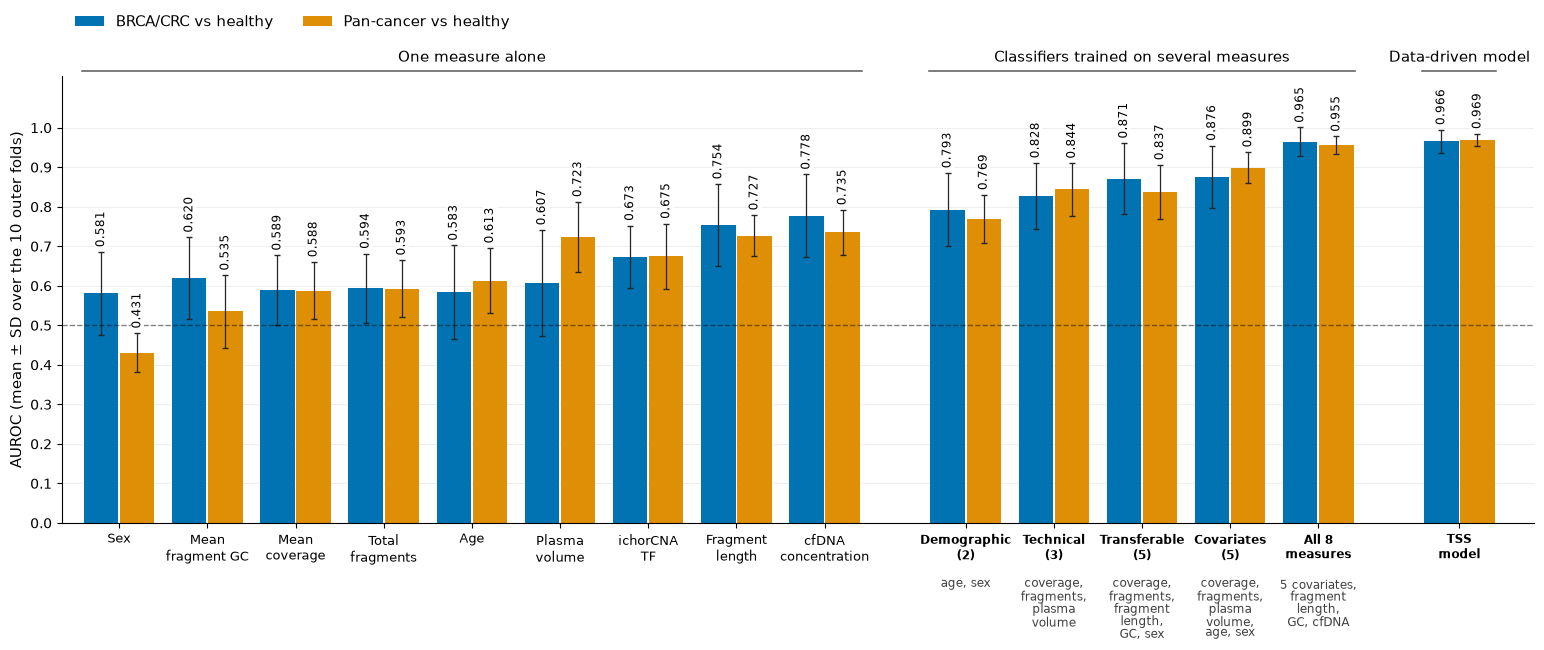

task,BRCA/CRC,PANCAN
method,,
bl_sex_female,0.581,0.431
bl_mean_gc,0.620,0.535
bl_mean_coverage,0.589,0.588
bl_total_fragments,0.594,0.593
bl_age,0.583,0.613
bl_plasma_volume,0.607,0.723
bl_ichorcna_tf,0.673,0.675
bl_fragment_length_mean,0.754,0.727
bl_cfdna_extracted,0.778,0.735


In [11]:
if all(HAVE_DD.values()):
    BAR_NAME = {"bl_mean_coverage": "Mean\ncoverage", "bl_total_fragments": "Total\nfragments", "bl_plasma_volume": "Plasma\nvolume",
                "bl_age": "Age", "bl_sex_female": "Sex", "bl_fragment_length_mean": "Fragment\nlength", "bl_mean_gc": "Mean\nfragment GC",
                "bl_cfdna_extracted": "cfDNA\nconcentration", "bl_ichorcna_tf": "ichorCNA\nTF",
                "bl_panel_technical3": "Technical\n(3)", "bl_panel_demographic": "Demographic\n(2)", "bl_panel_transfer5": "Transferable\n(5)",
                "bl_panel_techdemo5": "Covariates\n(5)", "bl_panel_all8": "All 8\nmeasures", "data_driven": "TSS\nmodel"}
    BAR_MEMBERS = {"bl_panel_technical3": "coverage,\nfragments,\nplasma\nvolume", "bl_panel_demographic": "age, sex",
                   "bl_panel_transfer5": "coverage,\nfragments,\nfragment\nlength,\nGC, sex",
                   "bl_panel_techdemo5": "coverage,\nfragments,\nplasma\nvolume,\nage, sex",
                   "bl_panel_all8": "5 covariates,\nfragment\nlength,\nGC, cfDNA"}
    BAR_TASKS = {"BRCA/CRC": ("BRCA/CRC vs healthy", "#0173B2"), "PANCAN": ("Pan-cancer vs healthy", "#DE8F05")}

    rows = []
    for task in TASKS:
        for m in list(BAR_NAME):
            aucs = np.array([x[2] for x in fold_rocs(arm(task, m))])
            assert len(aucs) == 10, (task, m, len(aucs))
            rows.append({"task": task, "method": m, "auroc_mean": aucs.mean(), "auroc_sd": aucs.std()})
    bars = pd.DataFrame(rows)
    bars.round(4).to_csv(os.path.join(_DATA, "figR2_measures_bars.csv"), index=False)
    mean_of = bars.groupby("method")["auroc_mean"].mean()
    singles = sorted([f"bl_{c}" for c in FIG_COVS], key=lambda m: mean_of[m])
    panels_ = sorted(FIG_PANELS, key=lambda m: mean_of[m])
    groups = [("One measure alone", singles), ("Classifiers trained on several measures", panels_), ("Data-driven model", ["data_driven"])]

    fig, ax = plt.subplots(figsize=(19, 5.8))
    x = 0.0; ticks, tick_m, spans = [], [], []
    width = 0.39
    for name, members in groups:
        x0 = x
        for m in members:
            for off, task in zip((-0.205, 0.205), TASKS):
                r = bars[(bars["task"] == task) & (bars["method"] == m)].iloc[0]
                ax.bar(x + off, r["auroc_mean"], width=width, color=BAR_TASKS[task][1], yerr=r["auroc_sd"],
                       error_kw={"elinewidth": 0.9, "capsize": 2, "ecolor": "0.15"})
                ax.text(x + off, r["auroc_mean"] + r["auroc_sd"] + 0.012, f"{r['auroc_mean']:.3f}", rotation=90, ha="center", va="bottom", fontsize=8.5,
                        bbox=dict(facecolor="white", edgecolor="none", pad=0.6), zorder=4)
            ticks.append(x); tick_m.append(m); x += 1
        spans.append((name, x0 - 0.5, x - 0.5))
        x += 0.6
    ax.set_xticks(ticks); ax.set_xticklabels([BAR_NAME[m] for m in tick_m], fontsize=9.4)
    for tick, m in zip(ax.get_xticklabels(), tick_m):
        if m.startswith("bl_panel") or m == "data_driven":
            tick.set_fontweight("bold"); tick.set_fontsize(8.6)
    trans = ax.get_xaxis_transform()
    for t_, m in zip(ticks, tick_m):
        if m in BAR_MEMBERS:
            ax.text(t_, -0.125, BAR_MEMBERS[m], transform=trans, ha="center", va="top", fontsize=8.4, color="0.25", linespacing=1.05)
    for name, a_, b_ in spans:
        ax.plot([a_ + 0.08, b_ - 0.08], [1.012, 1.012], transform=trans, color="0.35", linewidth=1.1, clip_on=False)
        ax.text((a_ + b_) / 2, 1.025, name, transform=trans, ha="center", va="bottom", fontsize=10.5)
    ax.axhline(0.5, color="k", linestyle="--", alpha=0.45, linewidth=1.0)
    ax.set_xlim(-0.65, x - 0.75); ax.set_ylim(0, 1.13); ax.set_yticks(np.arange(0, 1.01, 0.1))
    ax.set_ylabel("AUROC (mean \u00b1 SD over the 10 outer folds)", fontsize=10.5)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(handles=[Patch(facecolor=c_, label=l_) for l_, c_ in BAR_TASKS.values()], loc="lower left",
              bbox_to_anchor=(0.0, 1.075), ncol=2, frameon=False, fontsize=10.5)
    fig.savefig(out_path("figR2_measures_bars.png"), dpi=220, bbox_inches="tight")
    fig.savefig(out_path("figR2_measures_bars.pdf"), bbox_inches="tight")
    plt.show()
    display(bars.pivot(index="method", columns="task", values="auroc_mean").loc[tick_m].round(3))


## Further numbers

Values the sections above do not print: coverage by class, the 30 deep-sequenced controls (full-cohort
files `data/figS10_depth_subgroup.csv` and `data/figS8_predictions.csv`).

In [12]:
from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

if COHORT != "no_deep" or not all(HAVE_DD.values()):
    print("defined on the no_deep cohort with the data-driven arm exported")
else:
    print("Coverage, cancer versus healthy (Mann-Whitney)")
    for task in TASKS:
        sc = scalars[task]
        c, h = sc.loc[sc["y_true"] == 1, "mean_coverage"], sc.loc[sc["y_true"] == 0, "mean_coverage"]
        print(f"  {task}: median {c.median():.2f}x (cancer) vs {h.median():.2f}x (healthy), p = {mannwhitneyu(c, h).pvalue:.4f}")

    print("\nThe 30 deep-sequenced healthy controls against the other healthy donors (Cristiano et al. Table S1)")
    sub = pd.read_csv(os.path.join("data", "figS10_depth_subgroup.csv"))
    s1 = pd.read_excel(os.path.join("..", "..", "accessory_files", "cristiano_metadata.xlsx"), sheet_name="1", header=1)
    s1 = s1.drop_duplicates("Patient").set_index("Patient")
    hh = sub[sub["y_true"] == 0].assign(age=lambda t: t["sample_name"].map(s1["Age at Diagnosis"]),
                                       female=lambda t: t["sample_name"].map(s1["Gender"]).eq("F"))
    assert hh[["age"]].notna().all().all() and len(hh) == 194
    for deep, g in hh.groupby("deep_subgroup"):
        print(f"  {'deep-sequenced' if deep else 'other healthy'}: n = {len(g)}, median age {g['age'].median():.0f}, female {int(g['female'].sum())}/{len(g)} ({g['female'].mean():.0%})")

    print("\nFull cohort with the 30 included (Fig S8 export of the full cohort)")
    s8 = pd.read_csv(os.path.join("data", "figS8_predictions.csv"))
    deep30 = set(sub.loc[sub["deep_subgroup"], "sample_id"])
    for task, g in s8[s8["depth"] == "full"].groupby("task"):
        aucs = [roc_auc_score(f["y_true"], f["score"]) for _, f in g.groupby("fold")]
        print(f"  {task}: fold-mean AUROC {np.mean(aucs):.3f} ({len(g)} samples, {int((g['y_true'] == 0).sum())} healthy)")
    h8 = s8[(s8["y_true"] == 0) & s8["depth"].isin(["full", "cov1x"])].copy()
    h8["rank"] = h8.groupby(["task", "depth", "fold"])["score"].rank(pct=True)
    h8["deep"] = h8["sample_id"].isin(deep30)
    med = h8.groupby(["task", "depth", "deep"])["rank"].median().unstack("deep")
    print("  median within-fold percentile among the healthy samples (Fig S10d):")
    for (task, depth), r in med.iterrows():
        print(f"    {task} {depth}: deep-sequenced {r[True]:.3f}, other healthy {r[False]:.3f}")

Coverage, cancer versus healthy (Mann-Whitney)
  BRCA/CRC: median 2.57x (cancer) vs 2.32x (healthy), p = 0.0297
  PANCAN: median 2.52x (cancer) vs 2.32x (healthy), p = 0.0036

The 30 deep-sequenced healthy controls against the other healthy donors (Cristiano et al. Table S1)


  other healthy: n = 164, median age 54, female 111/164 (68%)
  deep-sequenced: n = 30, median age 46, female 30/30 (100%)

Full cohort with the 30 included (Fig S8 export of the full cohort)
  brca_crc: fold-mean AUROC 0.970 (274 samples, 194 healthy)
  pancan: fold-mean AUROC 0.954 (397 samples, 194 healthy)
  median within-fold percentile among the healthy samples (Fig S10d):
    brca_crc cov1x: deep-sequenced 0.526, other healthy 0.526
    brca_crc full: deep-sequenced 0.158, other healthy 0.579
    pancan cov1x: deep-sequenced 0.436, other healthy 0.526
    pancan full: deep-sequenced 0.150, other healthy 0.589
